<a href="https://colab.research.google.com/github/melanymogollon8-stack/RETO1/blob/main/Reto01_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<table style="border: none; border-collapse: collapse;">
    <tr>
        <td style="width: 20%; vertical-align: middle; padding-right: 10px;">
            <img src="https://i.imgur.com/nt7hloA.png" width="100">
        </td>
        <td style="width: 2px; text-align: center;">
            <font color="#0030A1" size="7">|</font><br>
            <font color="#0030A1" size="7">|</font>
        </td>
        <td>
            <p style="font-variant: small-caps;"><font color="#0030A1" size="5">
                <b>Carrera de Ciencia de Datos</b>
            </font> </p>
            <p style="font-variant: small-caps;"><font color="#0030A1" size="4">
                Aprendizaje Automático Inicial &bull; Reto 1: Aprendizaje no supervisado
            </font></p>
            <p style="font-style: oblique;"><font color="#0030A1" size="3">
                Melany Changoluisa &bull; 2026-2
            </font></p>
        </td>
    </tr>
</table>

---
## <font color='264CC7'> 1. Introducción </font>

**Ecuador y sus residuos: descubrir perfiles de gestión municipal.**

La gestión de residuos sólidos de un municipio incluye barrido, recolección, separación, aprovechamiento y disposición final. Comparar los 221 GAD municipales no es directo: sus operaciones van de unas pocas toneladas a más de cien mil toneladas al mes, y no todos reportan la misma información.

**Pregunta de análisis.** ¿Qué perfiles de gestión de residuos aparecen en los registros municipales del Ecuador y cómo comunicar sus diferencias para orientar preguntas y propuestas de mejora?

**Objetivos**
1. Auditar y preparar la base GIRS 2024 del INEC, distinguiendo ceros reales, datos faltantes y preguntas que no aplican.
2. Construir una matriz de pocas características que describan **prácticas** de gestión y no solo **tamaño**.
3. Agrupar los municipios con K-Means y con agrupamiento jerárquico, comparar varios valores de $k$ y evaluar su estabilidad.
4. Describir cada perfil en unidades originales y proponer acciones y necesidades de información.

**Alcance.** El análisis es exploratorio y usa una sola edición (2024). Los grupos **no** son un ranking de desempeño, ni una clasificación oficial, ni una medición causal. Tampoco bastan para asignar recursos.

**Técnicas utilizadas**
- **Estandarización** (`StandardScaler`): pone todas las características en la misma escala para que ninguna domine las distancias.
- **K-Means**: divide los datos en $k$ grupos minimizando la distancia de cada municipio al centro (centroide) de su grupo.
- **Agrupamiento jerárquico aglomerativo (Ward)**: une municipios paso a paso, y en cada paso hace la unión que menos aumenta la varianza interna. El dendrograma muestra cómo se forman los grupos.
- **Coeficiente de silueta**: mide, entre −1 y 1, qué tan cerca está cada municipio de su grupo frente al grupo vecino.
- **Índice de Rand ajustado (ARI)**: mide cuánto coinciden dos particiones (1 = idénticas, 0 = coincidencia al azar).
- **Análisis de componentes principales (PCA)**: se usa solo para **visualizar** los grupos en dos dimensiones.

Los paquetes necesarios son:

In [1]:
# Paquetes necesarios
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram
import warnings
warnings.filterwarnings('ignore', category=pd.errors.PerformanceWarning)   # avisos de rendimiento sin efecto en resultados

# Configuración general
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
sns.set_theme(style='whitegrid', font_scale=0.95)
SEMILLA = 42                                   # semilla principal (registrada)
COLORES = ['#2a78d6', '#eb6834', '#1baf7a', '#6250d6', '#e34948', '#008300']
MARCAS = ['o', 's', '^', 'D', 'v', 'P']        # forma + color: el grupo no depende solo del color

---
## <font color='264CC7'> 2. Fuente y exploración de los datos </font>

### 2.1 Registro de la fuente

| Elemento | Detalle |
|---|---|
| Fuente | INEC – *Estadística de Información Ambiental Económica en GAD Municipales: Gestión Integral de Residuos Sólidos* |
| Edición | 2024 (no se mezclan otras ediciones) |
| Archivo | `BDD_GIRS_2024_VF.csv` (dentro de `2_BDD_DATOS_ABIERTOS_GRS_GADM_2024_12_CSV.zip`) |
| Diccionario | `Diccionario de variables_GRS_2024.xlsx` |
| Fecha de creación de la base (metadatos INEC) | 26-12-2025 |
| Fecha de descarga | *[completar: dd-mm-2026]* |
| Portal | https://www.ecuadorencifras.gob.ec/gad-municipales/ |
| Copia de trabajo | https://github.com/melanymogollon8-stack/RETO1 |

Formato del archivo: separador `;`, decimales con coma y codificación Windows-1252 (`cp1252`). `CantonId` se lee como texto.

### 2.2 Carga y dimensiones

In [2]:
# Base original del INEC (copia en el repositorio del equipo)
URL_ORIGINAL = 'https://raw.githubusercontent.com/melanymogollon8-stack/RETO1/main/BDD_GIRS_2024_VF.csv'
# Base limpia generada con el código de la sección 3 (se usa solo para verificar)
URL_LIMPIA = 'https://raw.githubusercontent.com/melanymogollon8-stack/RETO1/main/BDD_GIRS_2024_limpia.csv'

df = pd.read_csv(URL_ORIGINAL, sep=';', decimal=',', encoding='cp1252',
                 dtype={'CantonId': str})
print('Dimensiones observadas:', df.shape)
display(df.iloc[:5, :8])

Dimensiones observadas: (221, 213)


,CantonId,NombreCantón,Provin,rgnatu,Pob,base,MR111,MR112
0,101,CUENCA,1,1,374870,1,2,2
1,102,GIRÓN,1,1,4491,1,2,2
2,103,GUALACEO,1,1,14336,1,2,2
3,104,NABÓN,1,1,1301,1,2,2
4,105,PAUTE,1,1,9056,1,1,2


### 2.3 Auditoría

Se verifica la unidad de observación (un registro por GAD municipal), los identificadores, los duplicados y que no existan filas de totales.

In [3]:
# El CSV guarda CantonId sin el cero inicial de la provincia ('101' en lugar de '0101')
print('Longitud de CantonId en el archivo:', df['CantonId'].str.len().value_counts().to_dict())
df['CantonId'] = df['CantonId'].str.strip().str.zfill(4)          # formato oficial PPCC

auditoria = pd.Series({
    'Registros': len(df),
    'Columnas': df.shape[1],
    'CantonId únicos': df['CantonId'].nunique(),
    'Filas duplicadas': df.duplicated().sum(),
    'Filas de totales': df['NombreCantón'].str.upper().str.contains('TOTAL').sum(),
    'CantonId coincide con Provin': (df['CantonId'].str[:2].astype(int) == df['Provin']).all(),
    'Nombres de cantón repetidos': df['NombreCantón'].duplicated().sum(),
})
display(auditoria.to_frame('Resultado'))
display(df[df['NombreCantón'].duplicated(keep=False)][['CantonId', 'NombreCantón', 'Provin']])

Longitud de CantonId en el archivo: {4: 123, 3: 98}


,Resultado
Registros,221
Columnas,213
CantonId únicos,221
Filas duplicadas,0
Filas de totales,0
CantonId coincide con Provin,True
Nombres de cantón repetidos,2


,CantonId,NombreCantón,Provin
30,0402,BOLÍVAR,4
119,1116,OLMEDO,11
134,1302,BOLÍVAR,13
150,1318,OLMEDO,13


Hay 221 registros, uno por cantón, con `CantonId` único y sin duplicados ni totales. Los nombres BOLÍVAR y OLMEDO se repiten, pero corresponden a cantones de provincias distintas; por eso el identificador es `CantonId` y no el nombre.

In [4]:
# Tipos de variables
print(df.dtypes.value_counts().to_string())

float64    128
int64       51
str         34


Las 213 columnas mezclan variables numéricas, categóricas codificadas (1 = Sí, 2 = No) y texto libre. Las categorías codificadas **no** se tratarán como cantidades continuas.

### 2.4 Disponibilidad de las variables candidatas

Se revisan las variables sugeridas por el reto y otras relacionadas: cuántos datos tienen, cuántos ceros y su unidad según el diccionario.

In [5]:
candidatas = {
    'CRR':   'Residuos recolectados (t/mes) = MR453 × 30',
    'MR453': 'Residuos recolectados (t/día)',
    'VB':    'Vías barridas (km) = MR42313 + MR42423',
    'CSB':   'Cobertura de barrido = VB / MR4223',
    'DIF':   'Recolección diferenciada (t/día) = MR4522 + MR4523',
    'TROT':  'Orgánicos tratados (t/mes) = (MR4441 + MR4442)/1000',
    'RI':    'Inorgánicos recuperados (kg/mes) = MR4341_TOTAL/12',
    'RIR':   'Inorgánicos recuperados (t/mes) = RI/1000',
    'MR4321':'Producción per cápita urbana (kg/hab/día)',
    'Pob':   'Población urbana proyectada (ref. 2022)',
    'PORG':  'Porcentaje de orgánicos (caracterización)',
}
disp = pd.DataFrame({
    'Descripción': candidatas,
    'Con dato': df[list(candidatas)].notna().sum(),
    'Faltantes': df[list(candidatas)].isna().sum(),
    'Ceros': (df[list(candidatas)] == 0).sum(),
    'Mínimo': df[list(candidatas)].min(),
    'Mediana': df[list(candidatas)].median(),
    'Máximo': df[list(candidatas)].max(),
})
display(disp)

,Descripción,Con dato,Faltantes,Ceros,Mínimo,Mediana,Máximo
CRR,Residuos recolectados (t/mes) = MR453 × 30,221,0,0,15.300,369.300,"121,905.600"
MR453,Residuos recolectados (t/día),221,0,0,0.510,12.310,"4,063.520"
VB,Vías barridas (km) = MR42313 + MR42423,221,0,2,0.000,18.110,"4,840.000"
CSB,Cobertura de barrido = VB / MR4223,216,5,1,0.000,1.000,2.130
DIF,Recolección diferenciada (t/día) = MR4522 + MR...,221,0,150,0.000,0.000,"2,000.000"
TROT,Orgánicos tratados (t/mes) = (MR4441 + MR4442)...,221,0,156,0.000,0.000,"9,939.790"
RI,Inorgánicos recuperados (kg/mes) = MR4341_TOTA...,221,0,134,0.000,0.000,"1,420,069.170"
RIR,Inorgánicos recuperados (t/mes) = RI/1000,221,0,138,0.000,0.000,"1,420.070"
MR4321,Producción per cápita urbana (kg/hab/día),221,0,0,0.230,0.620,1.410
Pob,Población urbana proyectada (ref. 2022),221,0,0,507.000,"9,032.000","2,853,214.000"


Observaciones:
- `CRR`, `VB`, `DIF`, `TROT`, `RI` y `MR4321` tienen dato en los 221 municipios. `CSB` tiene 5 vacíos y `PORG` solo 108 datos.
- `TROT` y `RI` tienen muchos ceros (156 y 134). Hay que distinguir si son *no realiza la actividad* o *no informó* (sección 3).
- Las escalas son muy distintas. `CRR` va de 15 a casi 122 000 t/mes, así que una distancia con valores absolutos quedaría dominada por los municipios grandes.

### 2.5 Distribuciones de las variables candidatas

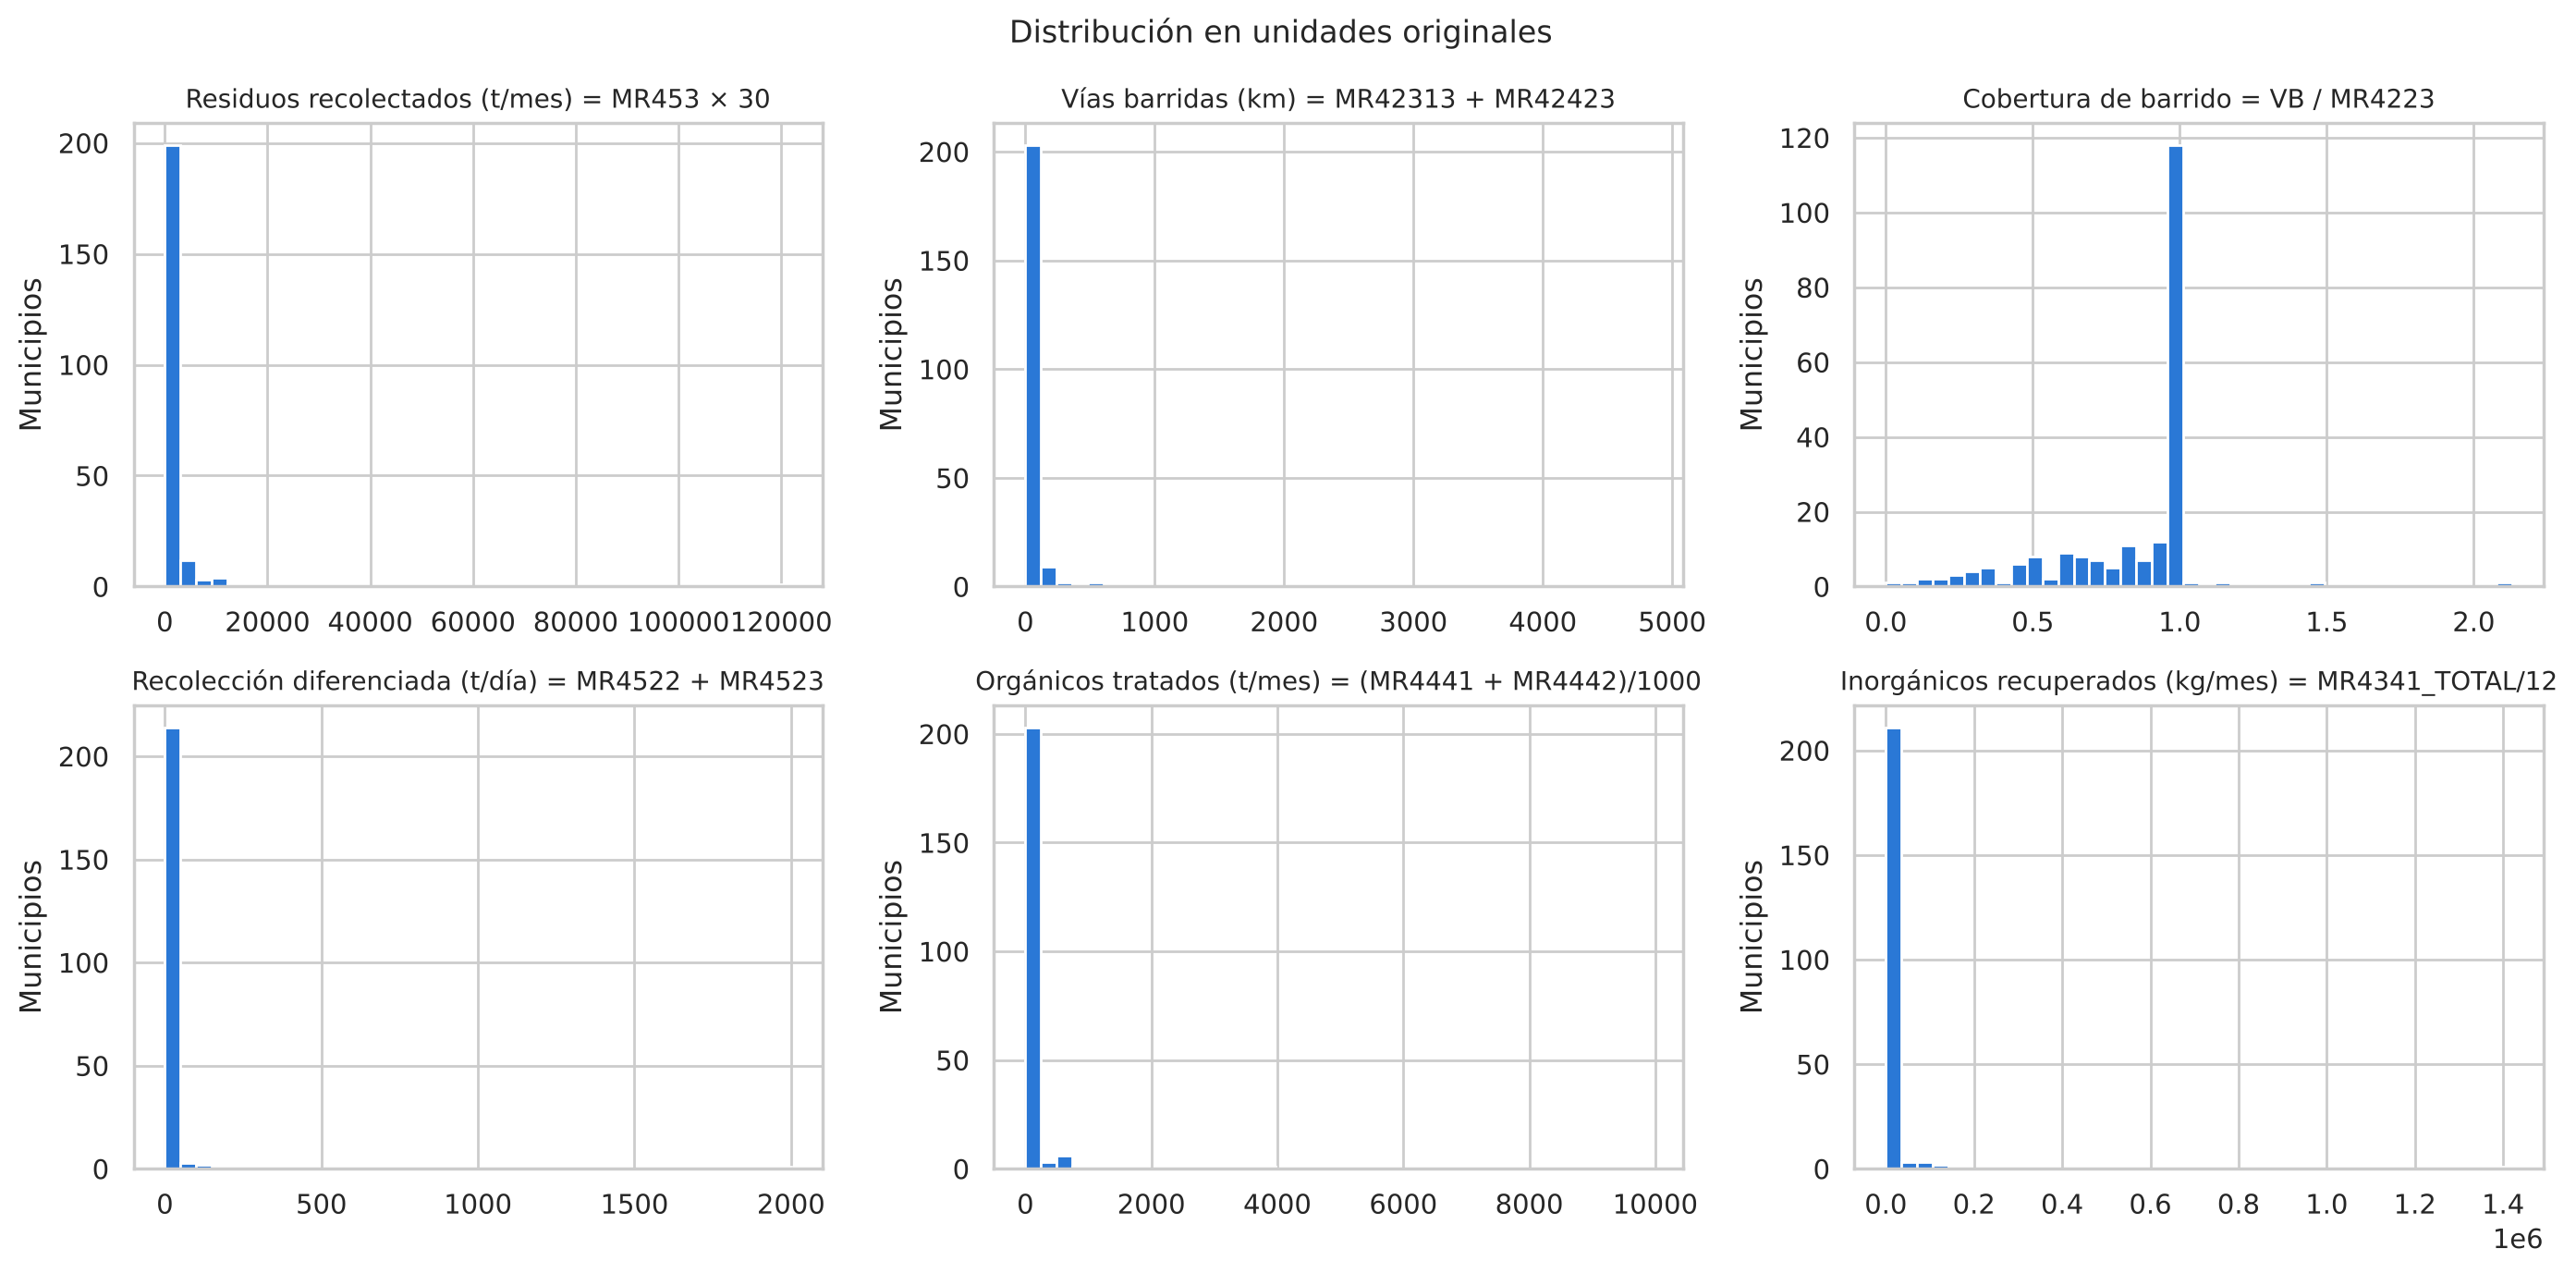

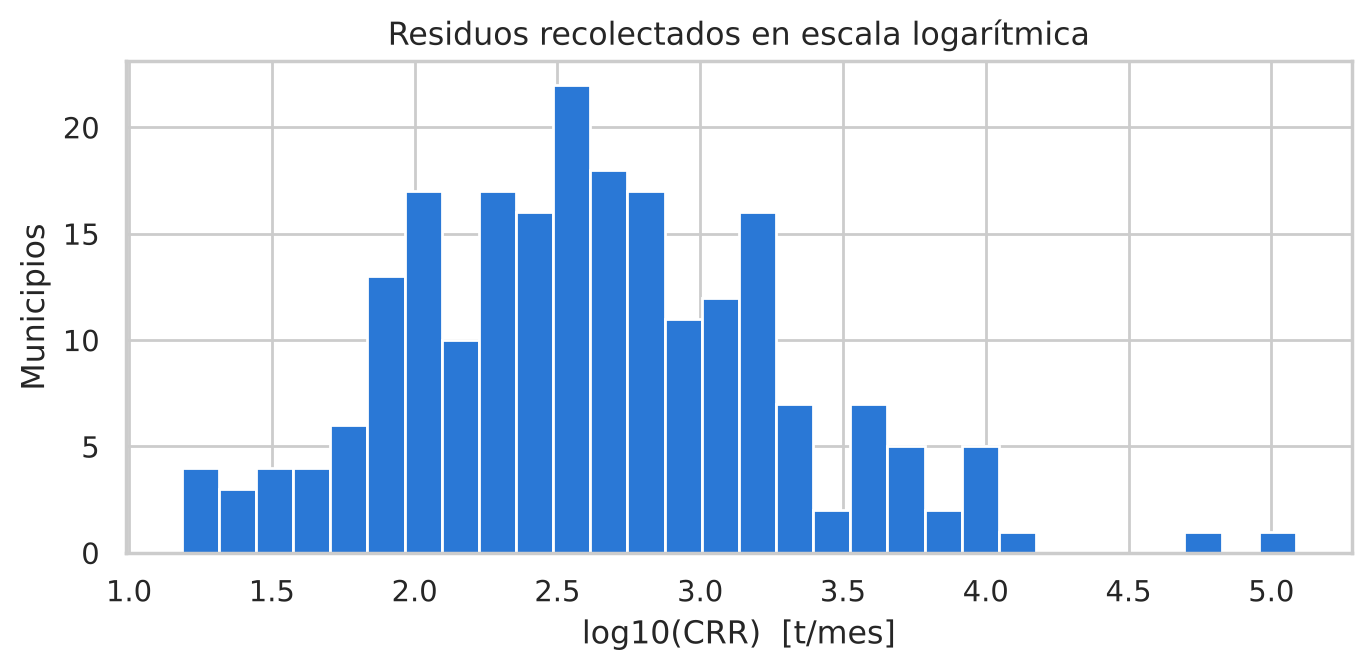

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
vars_hist = ['CRR', 'VB', 'CSB', 'DIF', 'TROT', 'RI']
for ax, v in zip(axes.ravel(), vars_hist):
    ax.hist(df[v].dropna(), bins=40, color=COLORES[0], edgecolor='white')
    ax.set_title(candidatas[v], fontsize=10)
    ax.set_ylabel('Municipios')
fig.suptitle('Distribución en unidades originales', fontsize=12)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(np.log10(df['CRR']), bins=30, color=COLORES[0], edgecolor='white')
ax.set_xlabel('log10(CRR)  [t/mes]'); ax.set_ylabel('Municipios')
ax.set_title('Residuos recolectados en escala logarítmica')
plt.tight_layout(); plt.show()

Las cantidades absolutas tienen una asimetría extrema: pocos municipios muy grandes (Guayaquil, Quito, Cuenca) y una mayoría pequeña. En escala logarítmica `CRR` se vuelve aproximadamente simétrica. `TROT`, `RI` y `DIF` son variables con exceso de ceros: la mayoría no realiza la actividad.

### 2.6 Diccionario de las características elegidas

Se eligen **5 características**: una describe la **escala** de la operación y cuatro describen **prácticas** de gestión como proporciones, para que no repitan el tamaño.

| Característica | Código original | Definición | Unidad | Transformación | Motivo de inclusión |
|---|---|---|---|---|---|
| `f_log10_CRR` | `CRR` (= `MR453`×30) | Residuos recolectados | t/mes | $\log_{10}$ | Escala de la operación. Cubre los 221 municipios. Reemplaza a `VB` y `Pob`, que repiten el tamaño (correlación 0,76 y 0,95 con log CRR). |
| `f_CSB` | `VB`, `MR4221`, `MR4222` | Cobertura de barrido: km barridos / km barribles | proporción 0–1 | Denominador recalculado (sección 3.1) | Práctica de limpieza pública, independiente del tamaño. |
| `f_prop_DIF` | `DIF`, `MR453` | Parte de la recolección que es diferenciada | proporción 0–1 | Ninguna | Práctica de separación. El cero es real cuando `MR452` = No. |
| `f_tasa_trat_org` | `TROT`, `CRR` | Orgánicos tratados / residuos recolectados | proporción | $\sqrt{x}$ | Aprovechamiento orgánico en términos relativos. |
| `f_tasa_recup_inorg` | `RI`, `CRR` | Inorgánicos recuperados / residuos recolectados | proporción | $\sqrt{x}$ | Reciclaje en términos relativos. Se usa `RI` y no `RIR` (es la misma información en otra unidad). |

**Variables que no se usan para agrupar:**
- `VB`, `Pob`, `MR48` y `MR465` repiten la escala.
- `RIR` es `RI` en otra unidad.
- `RGEN` se calcula con `Pob` y la producción per cápita, ambas estimadas.
- `Pob` es población **urbana** proyectada con referencia 2022, así que no sirve como denominador del servicio municipal.
- `PORG` y la composición solo existen en 108 municipios.

Las categorías (región, provincia, modelo de gestión, tipo de disposición final, balanza, separación en la fuente) se reservan para **describir** los grupos.

---
## <font color='264CC7'> 3. Preparación de los datos </font>

**Resumen de la limpieza.** La base limpia (`BDD_GIRS_2024_limpia.csv`) conserva los 221 municipios. Contiene sus identificadores, las variables originales y las características corregidas, y añade columnas de estado que distinguen **cero real**, **dato faltante** y **no aplica**. Las decisiones principales fueron:

1. **Identificador.** Se restauró `CantonId` a 4 dígitos.
2. **Barrido.** Se recalculó la longitud barrible con sus componentes urbano + rural y se corrigieron los valores de `CSB` mayores a 1 solo cuando hay una causa documentada.
3. **Orgánicos tratados.** Se separaron los ceros estructurales de los valores no confiables por la ambigüedad kg/año–kg/mes.
4. **Inorgánicos recuperados.** Se separaron los ceros reales, los casos que solo reportan neumáticos y las secciones sin respuesta.
5. **Matriz.** Se construyeron 5 características; 198 municipios las tienen completas.

A continuación se implementa cada paso y al final se verifica que el resultado coincide con la base limpia del repositorio.

### 3.1 Barrido: longitud barrible y cobertura

El INEC calcula `CSB = VB / MR4223`. La auditoría encontró tres problemas:
- 7 municipios donde el total `MR4223` **no coincide** con urbano + rural (`MR4221 + MR4222`).
- `CSB` mayor a 1 en 4 municipios.
- 5 valores vacíos.

In [7]:
# 1) Longitud barrible: el total reportado frente a la suma de sus componentes
long_comp = df['MR4221'].fillna(0) + df['MR4222'].fillna(0)
df['flag_long_inconsistente'] = (df['MR422'] == 1) & ((long_comp - df['MR4223']).abs() > 0.01)
display(df.loc[df['flag_long_inconsistente'],
               ['NombreCantón', 'MR4221', 'MR4222', 'MR4223', 'VB', 'CSB']])

,NombreCantón,MR4221,MR4222,MR4223,VB,CSB
35,LATACUNGA,39.990,0.800,27.460,40.160,1.460
44,COLTA,12.000,0.000,13.000,12.000,0.920
46,CHUNCHI,11.000,0.000,22.000,11.000,0.500
48,GUANO,6.000,0.000,12.000,6.000,0.500
97,ISIDRO AYORA,7.200,1.000,8.500,8.200,0.960
173,MERA,14.370,0.000,24.000,14.370,0.600
203,ISABELA,5.750,0.000,2.700,5.750,2.130


El total no coincide con la suma de sus partes. Se usa la **suma de componentes**, porque el formulario define el total como urbano + rural. En Latacunga e Isabela esto explica el `CSB` > 1. En Chunchi y Guano la cobertura sube de 0,50 a 1,00, así que conviene tenerlo presente al interpretar.

In [8]:
# 2) Denominador corregido: solo si el municipio definió la longitud barrible (MR422 = 1)
df['Long_barrible_km'] = long_comp.where((df['MR422'] == 1) & (long_comp > 0))
csb = df['VB'] / df['Long_barrible_km']

# 3) Valores > 1 que persisten
display(df.loc[csb > 1.001, ['NombreCantón', 'MR42313', 'MR42423', 'MR4241', 'VB', 'Long_barrible_km']]
          .assign(CSB_recalculado=csb[csb > 1.001]))

,NombreCantón,MR42313,MR42423,MR4241,VB,Long_barrible_km,CSB_recalculado
23,BIBLIÁN,60.000,10.000,1.000,70.000,60.000,1.167
28,SUSCAL,40.000,10.000,1.000,50.000,48.000,1.042


Solo quedan Biblián y Suscal por encima de 1. Ambos declaran que las rutas de barrido mecánico **repiten** las del barrido manual (`MR4241` = 1), así que sus kilómetros se suman dos veces en `VB`. Solo en esos dos casos la cobertura se lleva a 1; no es un recorte automático.

In [9]:
df['flag_CSB_solape_rutas'] = (csb > 1.001) & (df['MR4241'] == 1)
csb = csb.where(~df['flag_CSB_solape_rutas'], 1.0)
csb = csb.where(csb.round(6) != 1, 1.0)                  # ruido de redondeo (1.0000001)

# 4) Sin servicio de barrido (MR421 = 2): la cobertura real es 0
sin_servicio = df['MR421'] == 2
df['CSB_corr'] = csb.where(~sin_servicio, 0.0)

df['estado_barrido'] = np.select(
    [sin_servicio, df['CSB_corr'].isna()],
    ['sin_servicio (CSB=0)', 'faltante: longitud barrible no definida'], default='valido')
display(df['estado_barrido'].value_counts().to_frame('Municipios'))

,Municipios
estado_barrido,
valido,215
faltante: longitud barrible no definida,4
sin_servicio (CSB=0),2


### 3.2 Recolección diferenciada

`DIF` es la suma de orgánicos e inorgánicos recolectados de forma diferenciada (t/día) y `MR453` es el total recolectado (t/día). Las dos tienen la misma unidad, así que su cociente es válido. Cuando `MR452` = No, `DIF` = 0 es un **cero real**.

In [10]:
df['flag_DIF_supera_total'] = df['DIF'] > df['MR453']
display(df.loc[df['flag_DIF_supera_total'], ['NombreCantón', 'MR4522', 'MR4523', 'DIF', 'MR453']])
# Piñas reporta 0,4 t/día más de lo que recolecta en total: se acota el numerador al total
df['prop_DIF'] = np.minimum(df['DIF'], df['MR453']) / df['MR453']
print('¿Todos los DIF > 0 tienen MR452 = Sí?', ((df['DIF'] > 0) == (df['MR452'] == 1)).all())

,NombreCantón,MR4522,MR4523,DIF,MR453
61,PIÑAS,14.800,7.320,22.120,21.720


¿Todos los DIF > 0 tienen MR452 = Sí? True


### 3.3 Orgánicos tratados (`TROT`)

`TROT` (t/mes) proviene de `MR4441` y `MR4442`. La consigna advierte que el diccionario mezcla kg/año y kg/mes en `MR4441`. Por eso se contrasta `TROT` con lo recolectado.

In [11]:
no_aprovecha = (df['MR441'] == 2) & (df['MR442'] == 2)        # no aprovecha orgánicos de mercados ni domésticos
inconsistente = df['TROT'] > df['CRR']                           # trata más de lo que recolecta
faltante_trot = ~no_aprovecha & (df['TROT'] == 0)               # dice aprovechar, pero reporta 0

display(df.loc[inconsistente, ['NombreCantón', 'CRR', 'TROT', 'MR4441']]
          .assign(TROT_entre_CRR=df['TROT'] / df['CRR']).sort_values('TROT_entre_CRR', ascending=False).head(8))
print('Municipios con TROT > CRR:', inconsistente.sum())

,NombreCantón,CRR,TROT,MR4441,TROT_entre_CRR
182,PEDRO VICENTE MALDONADO,335.700,"2,489.420","2,489,419.200",7.416
99,ANTONIO ANTE,681.900,"3,721.560","3,721,560.000",5.458
193,ZAMORA,475.800,"2,446.640","2,446,642.000",5.142
26,EL TAMBO,99.900,503.000,"503,000.000",5.035
24,CAÑAR,400.800,"1,734.660","1,734,660.000",4.328
59,MARCABELÍ,133.800,541.770,"541,770.000",4.049
171,CARLOS JULIO AROSEMENA TOLA,56.100,208.650,"208,651.800",3.719
23,BIBLIÁN,177.300,647.710,"647,710.000",3.653


Municipios con TROT > CRR: 16


En 16 municipios `TROT` supera a lo recolectado; por ejemplo, Antonio Ante trata 5,5 veces lo que recolecta. Es coherente con que hayan reportado **kg/año** en un campo de kg/mes. No se divide entre 12, porque no se sabe qué unidad usó cada GAD. Esos valores se marcan como **no confiables** y quedan fuera de la matriz.

In [12]:
df['estado_TROT'] = np.select(
    [inconsistente, faltante_trot, no_aprovecha & (df['TROT'] == 0), df['TROT'] > 0],
    ['no_confiable: TROT > CRR (posible kg/año)', 'faltante: aprovecha pero sin cantidad',
     'cero_estructural: no aprovecha orgánicos', 'positivo'], default='positivo')
df['tasa_trat_org'] = (df['TROT'] / df['CRR']).where(~(inconsistente | faltante_trot))
display(df['estado_TROT'].value_counts().to_frame('Municipios'))

,Municipios
estado_TROT,
cero_estructural: no aprovecha orgánicos,155
positivo,49
no_confiable: TROT > CRR (posible kg/año),16
faltante: aprovecha pero sin cantidad,1


### 3.4 Inorgánicos recuperados (`RI`)

`RI` (kg/mes) es el total anual recuperado (`MR4341_TOTAL_RES_REC`, kg/año) dividido entre 12. `RIR` es lo mismo en toneladas, así que se usa solo una de las dos. El total en kg **no incluye neumáticos**, que se reportan en unidades/año.

In [13]:
flags_rec = [f'MR4341{i}' for i in range(1, 14)]            # ¿recupera papel, cartón, plástico, ...?
df['n_materiales_recuperados'] = (df[flags_rec] == 1).sum(axis=1)
sin_info_rec = df[flags_rec].isna().all(axis=1)                # sección completa sin responder
solo_neum = (df['n_materiales_recuperados'] > 0) & (df['MR4341_TOTAL_RES_REC'] == 0)

df['estado_RI'] = np.select(
    [sin_info_rec, df['RI'] > 0, solo_neum],
    ['faltante: sección sin respuesta', 'positivo',
     'cero: solo neumáticos (unidades, fuera del total en kg)'],
    default='cero_estructural: no recupera')
# Tasa en t/mes sobre t/mes: unidades compatibles
df['tasa_recup_inorg'] = (df['RI'] / 1000 / df['CRR']).where(~sin_info_rec)
display(df['estado_RI'].value_counts().to_frame('Municipios'))

,Municipios
estado_RI,
cero_estructural: no recupera,120
positivo,87
"cero: solo neumáticos (unidades, fuera del total en kg)",11
faltante: sección sin respuesta,3


### 3.5 Cero, dato faltante y pregunta que no aplica

| Situación | Ejemplo en la base | Tratamiento |
|---|---|---|
| **Cero real** (la actividad no se realiza) | `DIF` = 0 con `MR452` = No; `TROT` = 0 sin aprovechamiento de orgánicos; `RI` = 0 sin materiales recuperados | Se conserva el 0 |
| **No aplica** (la pregunta depende de un servicio que no existe) | Longitud barrible cuando no hay barrido (`MR421` = No) | La cobertura del servicio es 0 |
| **Dato faltante** (la actividad existe o se desconoce, pero no hay cantidad) | Barre pero no midió sus calles; aprovecha orgánicos y reporta 0 t; sección de reciclaje vacía | `NaN`: no se imputa |
| **Dato no confiable** | `TROT` > `CRR` (posible kg/año) | `NaN` y bandera |

Confundir estas situaciones cambiaría los perfiles. Por ejemplo, un municipio que no midió sus calles no tiene cobertura cero.

### 3.6 Características y registros conservados

In [14]:
df['f_log10_CRR'] = np.log10(df['CRR'])            # CRR > 0 en todos los municipios
df['f_CSB'] = df['CSB_corr']
df['f_prop_DIF'] = df['prop_DIF']
df['f_tasa_trat_org'] = df['tasa_trat_org']
df['f_tasa_recup_inorg'] = df['tasa_recup_inorg']
FEATURES = ['f_log10_CRR', 'f_CSB', 'f_prop_DIF', 'f_tasa_trat_org', 'f_tasa_recup_inorg']

df['incluir_matriz'] = df[FEATURES].notna().all(axis=1)
print(f"Municipios conservados en la matriz: {df['incluir_matriz'].sum()} de {len(df)}")
display(df.loc[~df['incluir_matriz'], FEATURES].isna().sum().to_frame('Faltantes entre los excluidos'))

Municipios conservados en la matriz: 198 de 221


,Faltantes entre los excluidos
f_log10_CRR,0
f_CSB,4
f_prop_DIF,0
f_tasa_trat_org,17
f_tasa_recup_inorg,3


Se conservan **198 de 221** municipios. Los 23 excluidos se deben a:
- 16 con `TROT` no confiable;
- 4 que barren sin longitud definida;
- 2 con la sección de reciclaje vacía;
- Chillanes, que no tiene la cantidad de orgánicos tratados ni la sección de reciclaje.

No se imputan para no inventar valores. En la sección 6 se les asigna un perfil tentativo con la información disponible.

**Verificación.** El resultado de esta sección debe coincidir con la base limpia publicada en el repositorio.

In [15]:
limpia = pd.read_csv(URL_LIMPIA, dtype={'CantonId': str})
comunes = [c for c in limpia.columns if c in df.columns]
pd.testing.assert_frame_equal(df[comunes].reset_index(drop=True), limpia[comunes],
                              check_dtype=False, check_exact=False, rtol=1e-9)
print(f'Coinciden {len(comunes)} columnas en los 221 registros.')

# Etiquetas de las categorías para describir los grupos (no entran en las distancias)
for c in ['Provincia', 'Region', 'Modelo_gestion', 'Disposicion_final',
          'Separacion_fuente', 'Balanza', 'Cobra_tasa', 'motivo_exclusion']:
    df[c] = limpia[c]

Coinciden 48 columnas en los 221 registros.


### 3.7 Atípicos y transformación

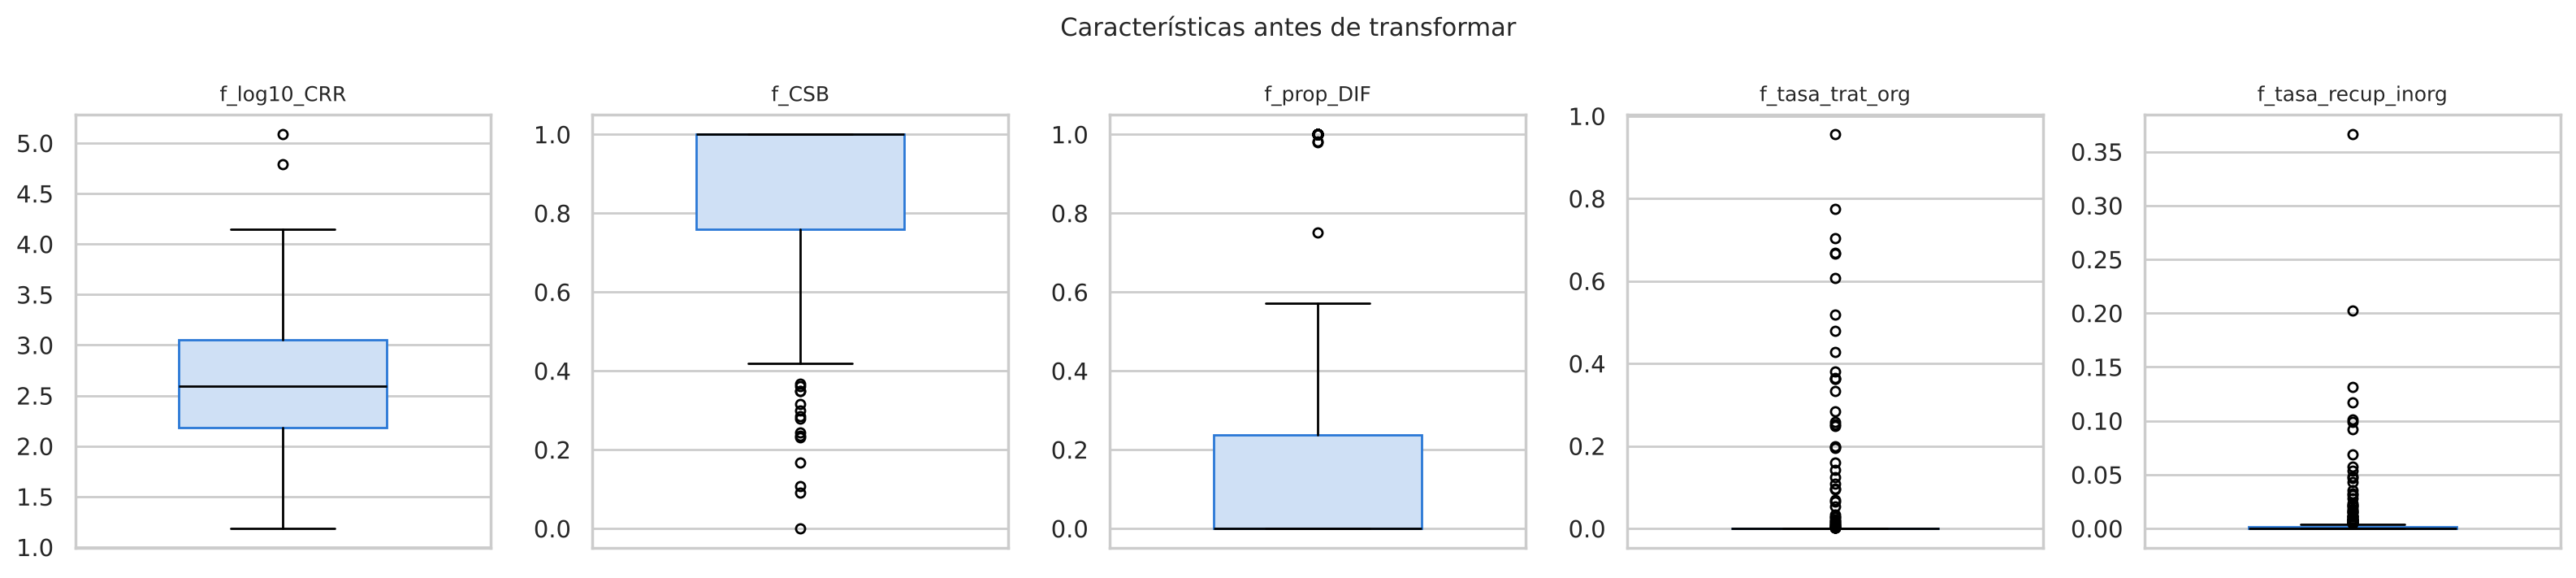

,count,mean,std,min,25%,50%,75%,max
f_log10_CRR,198.000,2.644,0.675,1.185,2.184,2.591,3.048,5.086
f_CSB,198.000,0.850,0.233,0.000,0.760,1.000,1.000,1.000
f_prop_DIF,198.000,0.241,0.420,0.000,0.000,0.000,0.238,1.000
f_tasa_trat_org,198.000,0.052,0.152,0.000,0.000,0.000,0.000,0.956
f_tasa_recup_inorg,198.000,0.010,0.035,0.000,0.000,0.000,0.002,0.366


Mayores tasas de recuperación de inorgánicos:


,NombreCantón,CRR,RI,f_tasa_recup_inorg
101,MACARÁ,369.300,"135,200.000",0.366
61,SAN LORENZO,750.000,"152,083.330",0.203
182,ISABELA,240.000,"31,500.000",0.131
143,GUALAQUIZA,90.000,"10,504.000",0.117


In [16]:
base = df[df['incluir_matriz']].reset_index(drop=True)

fig, axes = plt.subplots(1, 5, figsize=(16, 3.6))
for ax, f in zip(axes, FEATURES):
    ax.boxplot(base[f], widths=0.5, patch_artist=True,
               boxprops=dict(facecolor='#cfe0f5', color=COLORES[0]),
               medianprops=dict(color='black'), flierprops=dict(marker='o', markersize=4))
    ax.set_title(f, fontsize=9); ax.set_xticks([])
fig.suptitle('Características antes de transformar', fontsize=11)
plt.tight_layout(); plt.show()

display(base[FEATURES].describe().T)
print('Mayores tasas de recuperación de inorgánicos:')
display(base.nlargest(4, 'f_tasa_recup_inorg')[['NombreCantón', 'CRR', 'RI', 'f_tasa_recup_inorg']])

Las dos tasas (tratamiento orgánico y recuperación de inorgánicos) tienen mediana 0 y unos pocos valores muy altos; Macará, por ejemplo, recupera 37 % de lo que recolecta. **No se eliminan** atípicos: son municipios reales y quitarlos solo para mejorar la silueta va contra el reto. En su lugar se aplica **raíz cuadrada** a las dos tasas. Con ella los valores pequeños se separan mejor y los extremos pesan menos, sin cambiar el orden de los municipios ni el significado del cero. `f_prop_DIF` no se transforma porque casi todos sus valores son 0 o cercanos a 1.

Después se **estandariza** cada característica (media 0, desviación 1), para que todas pesen lo mismo en la distancia euclidiana.

Matriz preparada: (198, 5)


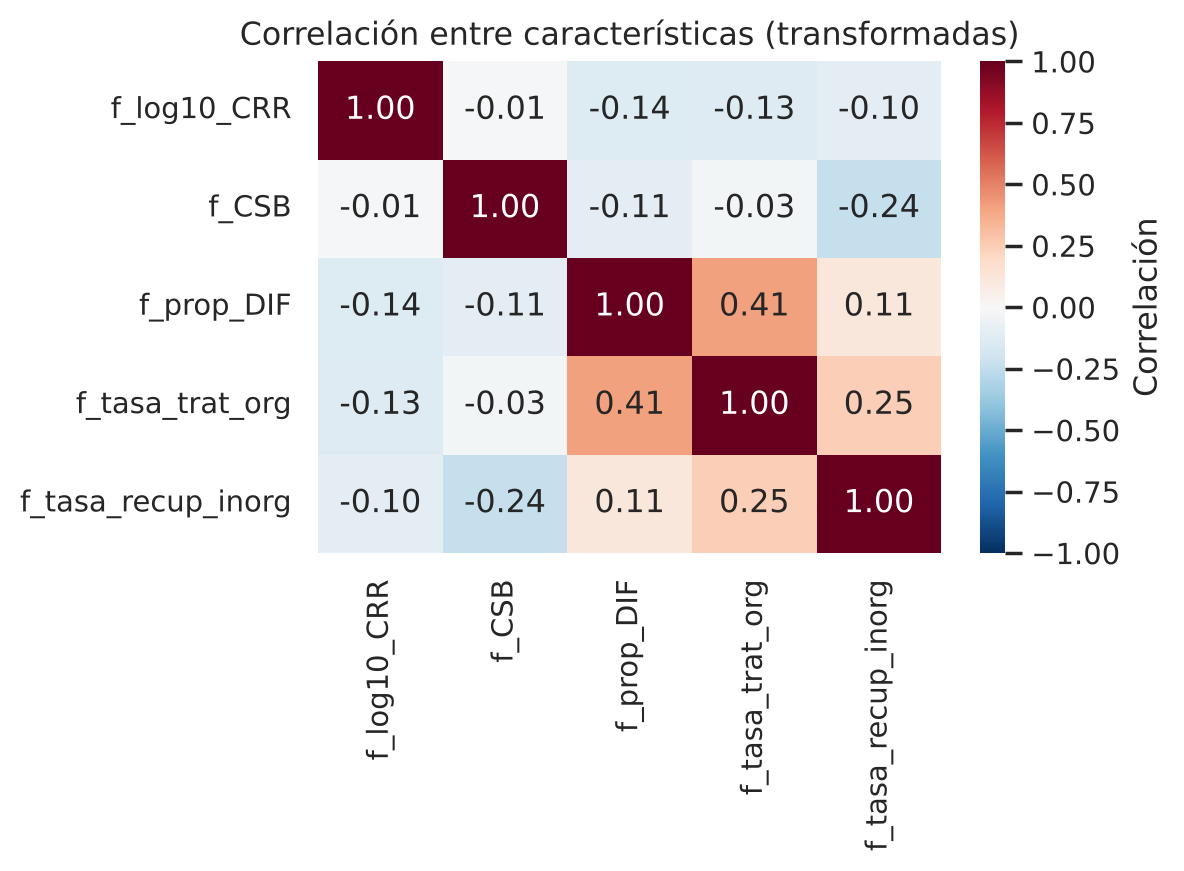

In [17]:
X = base[FEATURES].copy()
X['f_tasa_trat_org'] = np.sqrt(X['f_tasa_trat_org'])
X['f_tasa_recup_inorg'] = np.sqrt(X['f_tasa_recup_inorg'])

escalador = StandardScaler()
Z = escalador.fit_transform(X)                 # matriz preparada: se usa para agrupar y para TODAS las métricas
print('Matriz preparada:', Z.shape)

fig, ax = plt.subplots(figsize=(6, 4.5))
sns.heatmap(X.corr(), annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=ax,
            cbar_kws={'label': 'Correlación'})
ax.set_title('Correlación entre características (transformadas)')
plt.tight_layout(); plt.show()

Las correlaciones entre características son bajas: la mayor es 0,41, entre recolección diferenciada y tratamiento orgánico. Ninguna repite a otra, y la escala (`f_log10_CRR`) casi no se relaciona con las prácticas (|r| ≤ 0,14).

---
## <font color='264CC7'> 4. Agrupamiento </font>

Configuración:
- **K-Means**: `n_init=50` (50 inicializaciones, se queda la de menor inercia), `random_state=42`, $k = 2, \dots, 6$.
- **Jerárquico**: enlace **Ward** con distancia **euclidiana**, sobre la misma matriz `Z`. Ward une los grupos que menos aumentan la varianza interna, igual que el criterio que minimiza K-Means, así que las dos soluciones son comparables. Las variables están estandarizadas, de modo que la distancia euclidiana es apropiada. Como contraste se prueba también el enlace promedio.

### 4.1 K-Means para k = 2, …, 6

In [18]:
K_VALORES = range(2, 7)
res, etiquetas_km, etiquetas_w = [], {}, {}
for k in K_VALORES:
    km = KMeans(n_clusters=k, n_init=50, random_state=SEMILLA).fit(Z)
    w = AgglomerativeClustering(n_clusters=k, linkage='ward').fit(Z)
    etiquetas_km[k], etiquetas_w[k] = km.labels_, w.labels_
    res.append({'k': k,
                'Inercia K-Means': km.inertia_,
                'Silueta K-Means': silhouette_score(Z, km.labels_),
                'Tamaños K-Means': sorted(np.bincount(km.labels_), reverse=True),
                'Silueta Ward': silhouette_score(Z, w.labels_),
                'Tamaños Ward': sorted(np.bincount(w.labels_), reverse=True),
                'ARI K-Means vs Ward': adjusted_rand_score(km.labels_, w.labels_)})
comparacion = pd.DataFrame(res).set_index('k')
display(comparacion)

,Inercia K-Means,Silueta K-Means,Tamaños K-Means,Silueta Ward,Tamaños Ward,ARI K-Means vs Ward
k,,,,,,
2,733.487,0.390,"[139, 59]",0.379,"[133, 65]",0.841
3,605.971,0.401,"[124, 54, 20]",0.357,"[133, 37, 28]",0.644
4,500.409,0.407,"[122, 32, 23, 21]",0.384,"[133, 28, 22, 15]",0.742
5,415.909,0.398,"[110, 32, 25, 22, 9]",0.368,"[112, 28, 22, 21, 15]",0.902
6,346.902,0.345,"[68, 46, 28, 24, 23, 9]",0.310,"[61, 51, 28, 22, 21, 15]",0.691


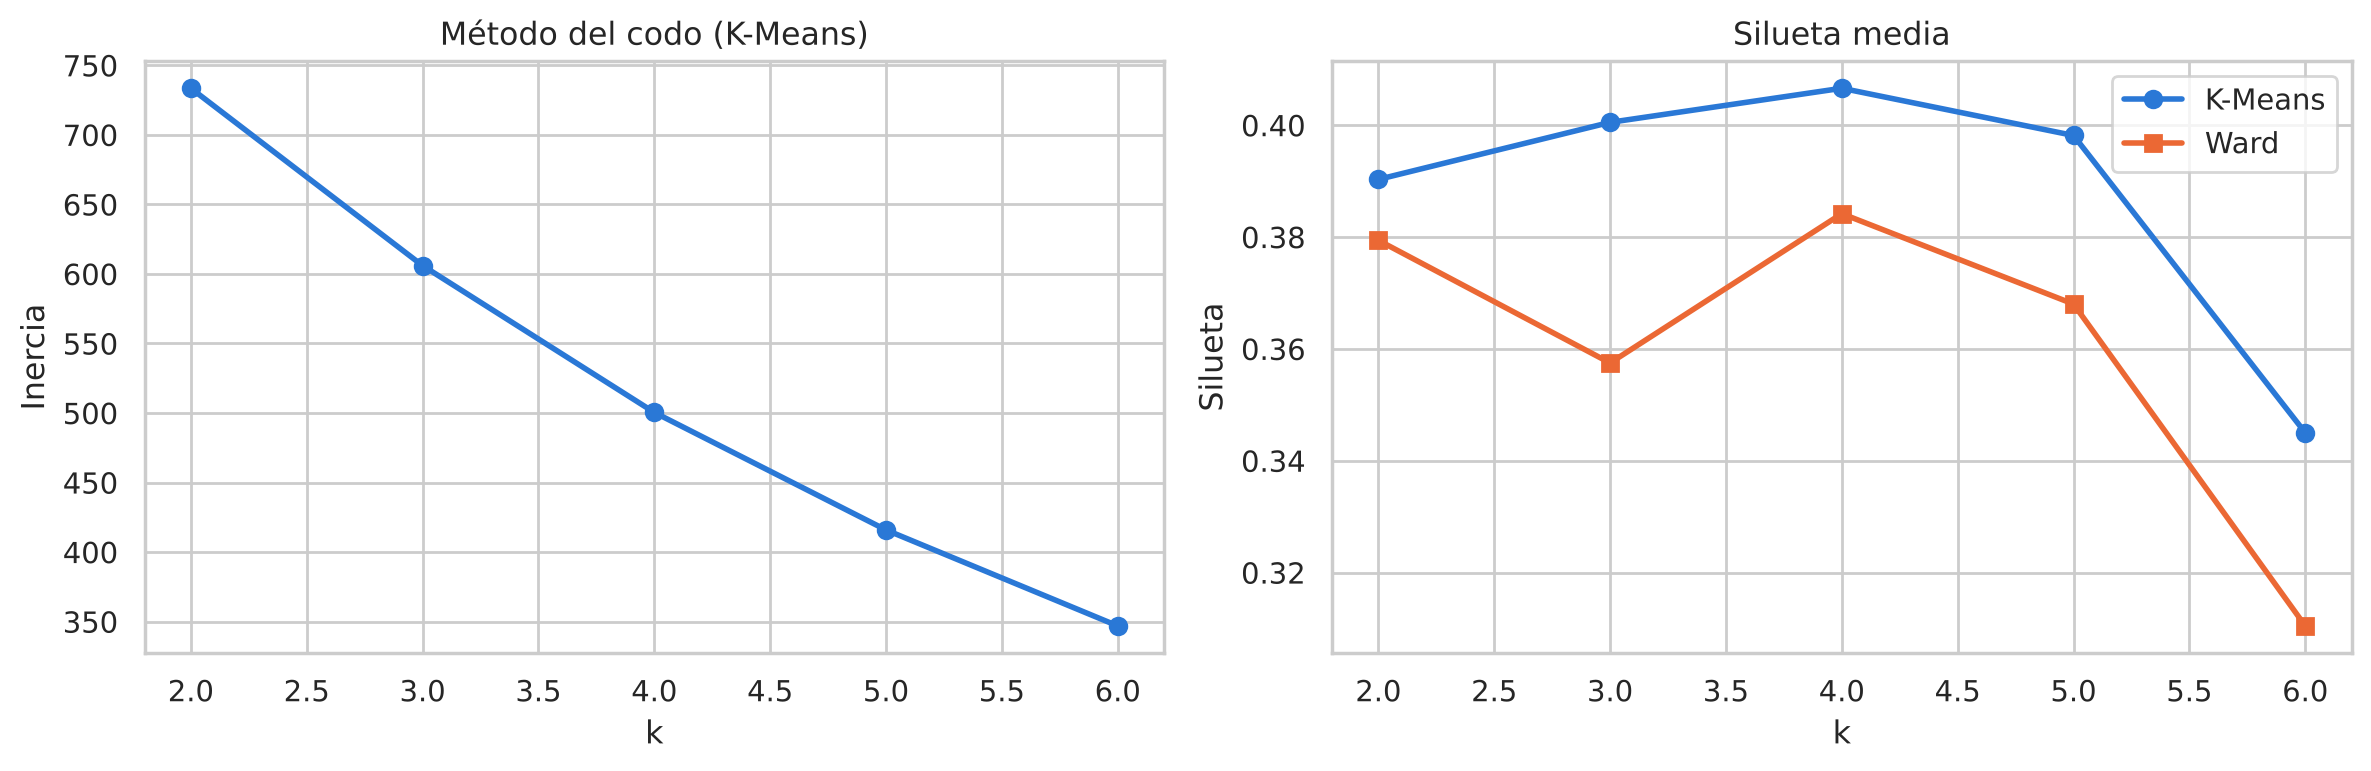

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(comparacion.index, comparacion['Inercia K-Means'], marker='o', color=COLORES[0], lw=2)
axes[0].set(title='Método del codo (K-Means)', xlabel='k', ylabel='Inercia')
axes[1].plot(comparacion.index, comparacion['Silueta K-Means'], marker='o', lw=2, color=COLORES[0], label='K-Means')
axes[1].plot(comparacion.index, comparacion['Silueta Ward'], marker='s', lw=2, color=COLORES[1], label='Ward')
axes[1].set(title='Silueta media', xlabel='k', ylabel='Silueta'); axes[1].legend()
plt.tight_layout(); plt.show()

Para $k$ entre 2 y 5 la silueta es parecida (≈ 0,39–0,41) y cae en $k = 6$. El codo no es marcado. Ninguna métrica elige $k$ por sí sola, así que la decisión también considera los tamaños y la interpretación (sección 4.4).

### 4.2 Agrupamiento jerárquico: dendrograma y enlace

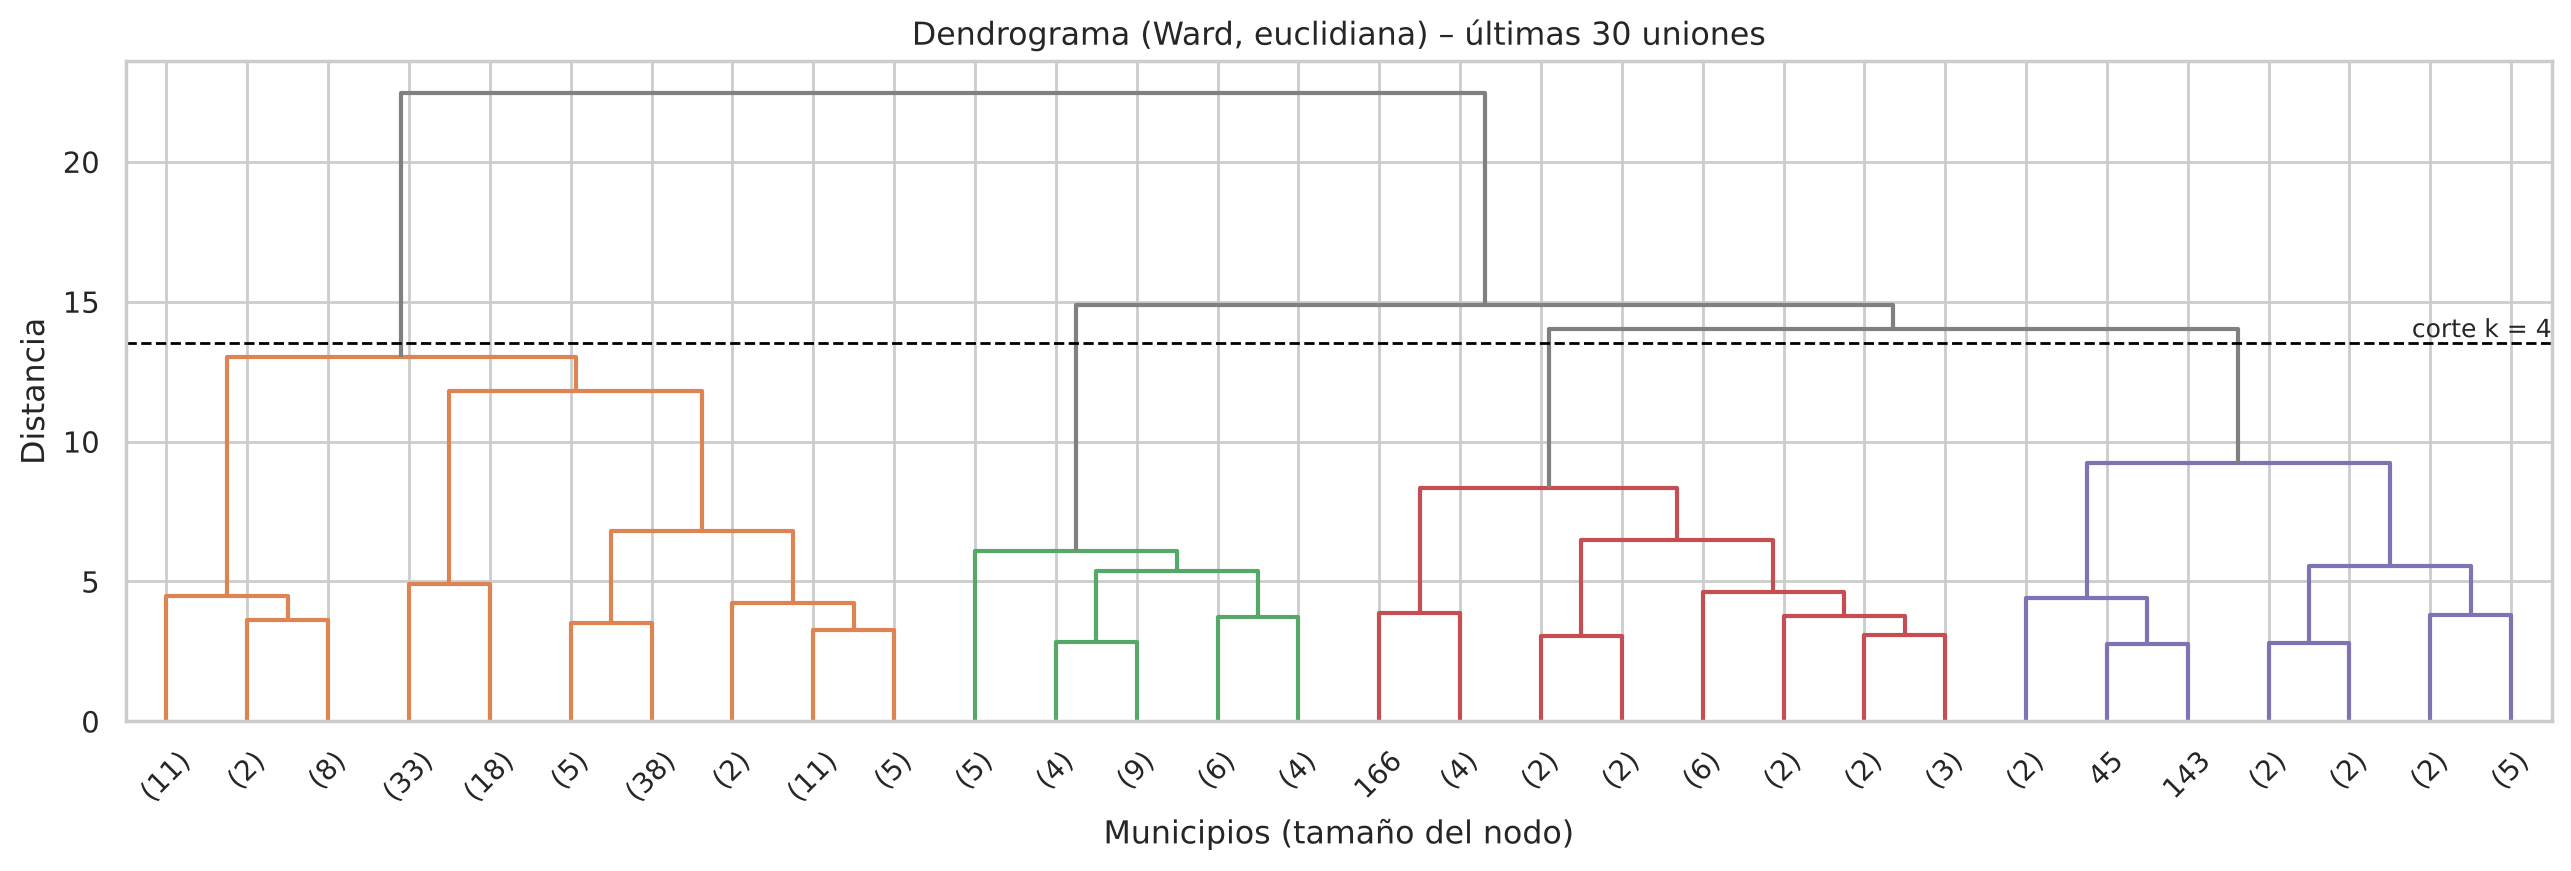

Enlace promedio, k=3: tamaños [np.int64(170), np.int64(24), np.int64(4)], silueta 0.427
Enlace promedio, k=4: tamaños [np.int64(169), np.int64(24), np.int64(4), np.int64(1)], silueta 0.368


In [20]:
Lw = linkage(Z, method='ward', metric='euclidean')
fig, ax = plt.subplots(figsize=(13, 4.5))
corte = (Lw[-4, 2] + Lw[-3, 2]) / 2            # altura que deja exactamente 4 grupos
dendrogram(Lw, truncate_mode='lastp', p=30, color_threshold=corte, ax=ax,
           above_threshold_color='grey')
ax.axhline(corte, ls='--', color='black', lw=1)
ax.text(ax.get_xlim()[1], corte, ' corte k = 4', va='bottom', ha='right', fontsize=9)
ax.set(title='Dendrograma (Ward, euclidiana) – últimas 30 uniones', xlabel='Municipios (tamaño del nodo)', ylabel='Distancia')
plt.tight_layout(); plt.show()

# Contraste: enlace promedio
for k in [3, 4]:
    h = AgglomerativeClustering(n_clusters=k, linkage='average').fit_predict(Z)
    print(f'Enlace promedio, k={k}: tamaños {sorted(np.bincount(h), reverse=True)}, '
          f'silueta {silhouette_score(Z, h):.3f}')

El dendrograma muestra cuatro ramas claras antes de que las distancias de unión crezcan (línea punteada). El **enlace promedio** obtiene una silueta similar o mayor, pero forma un grupo enorme (≈ 170 municipios) y aísla 1 a 4 atípicos, lo que no ayuda a describir perfiles. Por eso se prefiere **Ward**.

### 4.3 Estabilidad frente a la inicialización de K-Means

In [21]:
SEMILLAS = list(range(30))                     # semillas registradas: 0, 1, ..., 29
estab = []
for k in K_VALORES:
    ref = etiquetas_km[k]
    ari_1 = [adjusted_rand_score(ref, KMeans(k, n_init=1, random_state=s).fit_predict(Z)) for s in SEMILLAS]
    sil_1 = [silhouette_score(Z, KMeans(k, n_init=1, random_state=s).fit_predict(Z)) for s in SEMILLAS]
    ari_10 = [adjusted_rand_score(ref, KMeans(k, n_init=10, random_state=s).fit_predict(Z)) for s in SEMILLAS]
    estab.append({'k': k,
                  'ARI medio (1 inicialización)': np.mean(ari_1),
                  'ARI mínimo (1 inicialización)': np.min(ari_1),
                  'Silueta mín–máx (1 inicialización)': f'{min(sil_1):.3f} – {max(sil_1):.3f}',
                  'ARI medio (10 inicializaciones)': np.mean(ari_10),
                  'ARI mínimo (10 inicializaciones)': np.min(ari_10)})
display(pd.DataFrame(estab).set_index('k'))

,ARI medio (1 inicialización),ARI mínimo (1 inicialización),Silueta mín–máx (1 inicialización),ARI medio (10 inicializaciones),ARI mínimo (10 inicializaciones)
k,,,,,
2,0.763,-0.014,0.218 – 0.402,0.999,0.979
3,0.681,0.219,0.203 – 0.410,0.935,0.680
4,0.617,0.317,0.240 – 0.407,0.978,0.761
5,0.627,0.406,0.271 – 0.412,0.994,0.925
6,0.821,0.547,0.309 – 0.414,0.975,0.842


Con **una sola** inicialización, K-Means puede caer en soluciones locales distintas: el ARI medio frente a la solución de referencia queda entre 0,6 y 0,8 y algunas semillas dan particiones muy diferentes. La silueta también varía mucho. Con **10 inicializaciones** las 30 semillas reproducen casi la misma partición: para $k = 4$ el ARI medio es 0,98 y el mínimo 0,76. La conclusión es usar siempre varias inicializaciones; con ellas, la semilla no cambia los perfiles.

In [22]:
# Estabilidad frente a los datos: se repite K-Means (k=4) sobre submuestras del 80 %
rng = np.random.default_rng(SEMILLA)
ref4 = etiquetas_km[4]
ari_sub = []
for r in range(50):
    idx = rng.choice(len(Z), int(0.8 * len(Z)), replace=False)
    lab = KMeans(4, n_init=10, random_state=r).fit_predict(Z[idx])
    ari_sub.append(adjusted_rand_score(ref4[idx], lab))
print(f'Submuestras 80 % (k=4): ARI medio {np.mean(ari_sub):.2f}, mediana {np.median(ari_sub):.2f}, mínimo {np.min(ari_sub):.2f}')

Submuestras 80 % (k=4): ARI medio 0.86, mediana 0.86, mínimo 0.63


Al quitar al azar el 20 % de los municipios, la partición en 4 grupos se mantiene en buena medida (ARI medio ≈ 0,86, mínimo ≈ 0,63). Algunas submuestras la reorganizan, porque los límites entre grupos vecinos no son nítidos.

### 4.4 Elección de la solución

| Criterio | k = 3 | **k = 4** | k = 5 |
|---|---|---|---|
| Silueta K-Means | ≈ 0,40 | **≈ 0,41** (la más alta) | ≈ 0,40 |
| Tamaños | 124 / 54 / 20 | **122 / 32 / 23 / 21** | 110 / 32 / 25 / 22 / 9 |
| Acuerdo con Ward (ARI) | ≈ 0,6 | **≈ 0,7** | ≈ 0,9 |
| Interpretación | Mezcla en un grupo a quienes diferencian y tratan orgánicos con quienes solo diferencian | **Separa cuatro prácticas distintas** | Añade un grupo de 9 municipios pequeños con alta recuperación de inorgánicos |

Se elige **K-Means con k = 4**. Tiene la silueta más alta, ningún grupo es diminuto, Ward llega a una partición parecida y cada grupo tiene una interpretación clara. $k = 5$ es una alternativa razonable y se comenta en la discusión de estabilidad.

In [23]:
K_FINAL = 4
km_final = KMeans(n_clusters=K_FINAL, n_init=50, random_state=SEMILLA).fit(Z)
w_final = etiquetas_w[K_FINAL]
print('Tabla cruzada K-Means (filas) vs Ward (columnas), k = 4')
display(pd.crosstab(km_final.labels_, w_final, rownames=['K-Means'], colnames=['Ward']))

Tabla cruzada K-Means (filas) vs Ward (columnas), k = 4


Ward,0,1,2,3
K-Means,,,,
0,13,6,1,1
1,119,3,0,0
2,0,3,0,20
3,1,3,27,1


### 4.5 Nombres de los grupos y calidad de la solución

In [24]:
# Los números de K-Means son arbitrarios. Se nombra cada grupo según sus características
# (sin orden de calidad), usando reglas sobre los centroides en unidades originales.
base['grupo_num'] = km_final.labels_
cent = base.groupby('grupo_num')[FEATURES].mean()

nombres = {}
g = cent['f_CSB'].idxmin();                                   nombres[g] = 'Barrido limitado'
resto = cent.drop(list(nombres))
g = resto['f_tasa_trat_org'].idxmax();                        nombres[g] = 'Separación con aprovechamiento orgánico'
resto = resto.drop(g)
g = resto['f_prop_DIF'].idxmax();                             nombres[g] = 'Recolección diferenciada sin tratamiento'
g = resto.drop(g).index[0];                                   nombres[g] = 'Servicio convencional'
ORDEN = ['Servicio convencional', 'Recolección diferenciada sin tratamiento',
         'Separación con aprovechamiento orgánico', 'Barrido limitado']
base['grupo'] = pd.Categorical(base['grupo_num'].map(nombres), categories=ORDEN)
COLOR_G = dict(zip(ORDEN, COLORES)); MARCA_G = dict(zip(ORDEN, MARCAS))
display(base['grupo'].value_counts().reindex(ORDEN).to_frame('Municipios'))

,Municipios
grupo,
Servicio convencional,122
Recolección diferenciada sin tratamiento,32
Separación con aprovechamiento orgánico,23
Barrido limitado,21


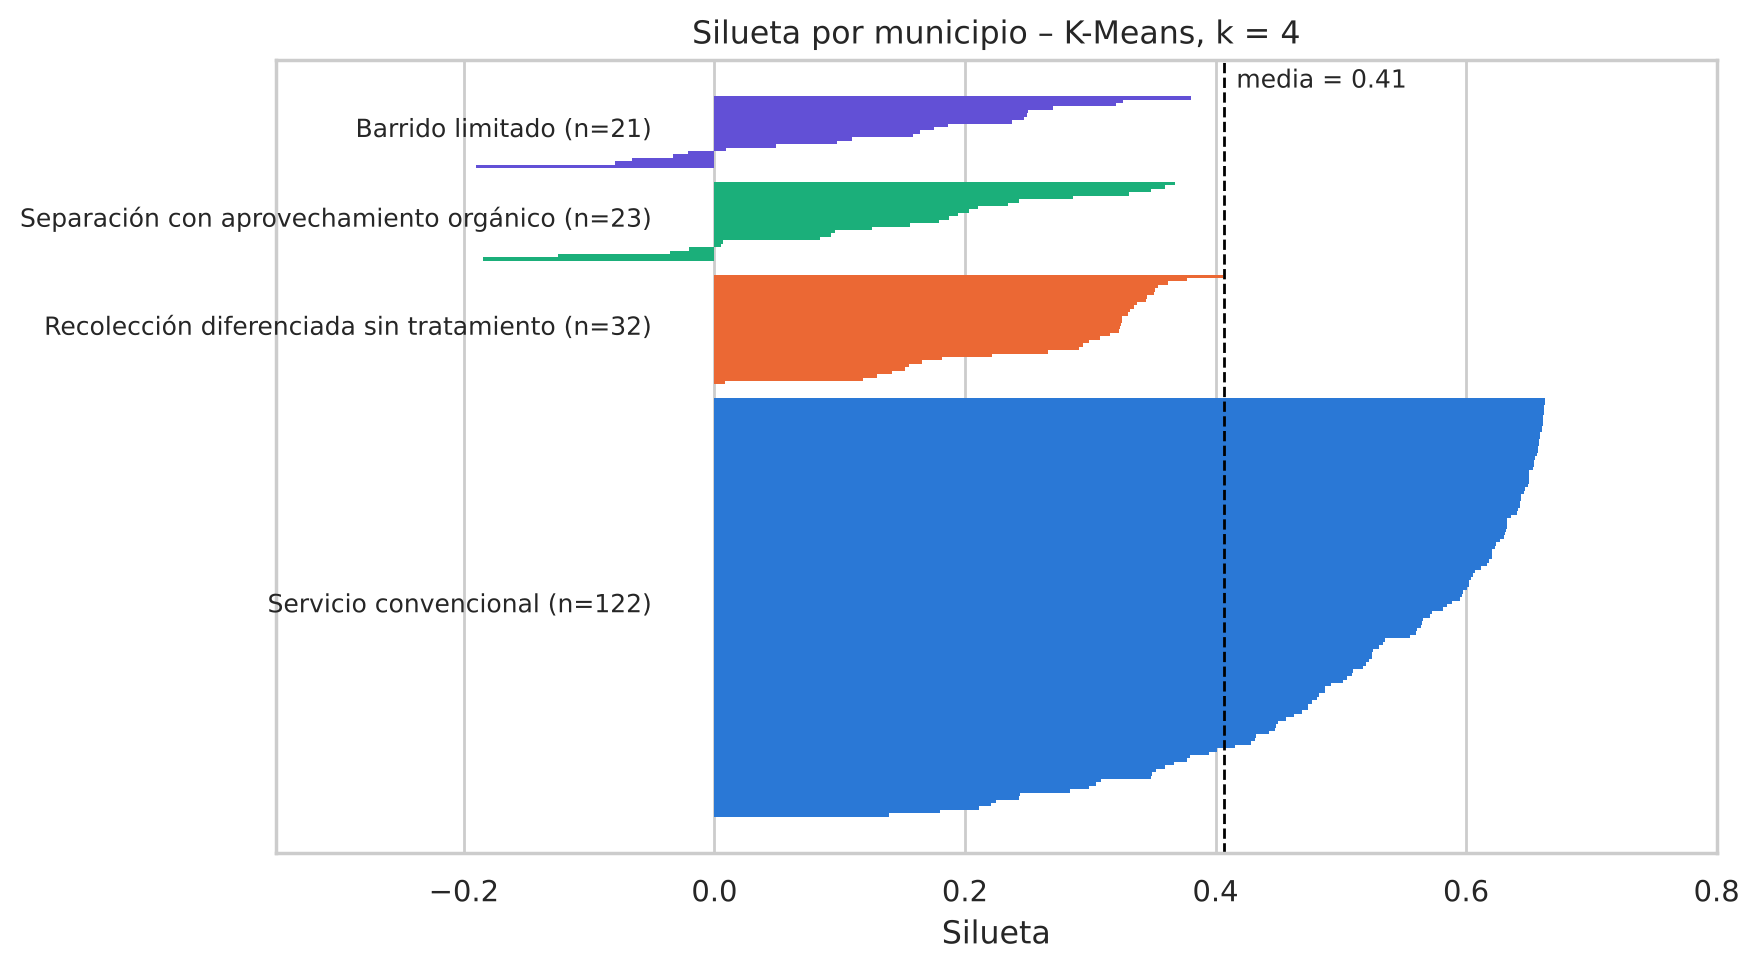

,Silueta media,Mínima,Municipios con silueta < 0
grupo,,,
Servicio convencional,0.536,0.139,0
Recolección diferenciada sin tratamiento,0.278,0.008,0
Separación con aprovechamiento orgánico,0.146,-0.185,4
Barrido limitado,0.135,-0.191,5


In [25]:
# Gráfico de silueta por municipio (calculado en la matriz Z)
base['silueta'] = silhouette_samples(Z, km_final.labels_)
fig, ax = plt.subplots(figsize=(9, 5))
y = 0
for gname in ORDEN:
    s = np.sort(base.loc[base['grupo'] == gname, 'silueta'])
    ax.barh(np.arange(y, y + len(s)), s, height=1.0, color=COLOR_G[gname], edgecolor='none')
    ax.text(-0.05, y + len(s) / 2, f'{gname} (n={len(s)})', ha='right', va='center', fontsize=9)
    y += len(s) + 4
ax.axvline(base['silueta'].mean(), ls='--', color='black', lw=1)
ax.text(base['silueta'].mean() + 0.01, y - 2, f"media = {base['silueta'].mean():.2f}", fontsize=9)
ax.set(yticks=[], xlabel='Silueta', title='Silueta por municipio – K-Means, k = 4')
ax.set_xlim(-0.35, 0.8)
plt.tight_layout(); plt.show()

display(base.groupby('grupo', observed=True)['silueta'].agg(['mean', 'min', lambda s: (s < 0).sum()])
            .rename(columns={'mean': 'Silueta media', 'min': 'Mínima', '<lambda_0>': 'Municipios con silueta < 0'}))

**Calidad de los grupos.** El *Servicio convencional* es compacto, con silueta media alta. Los otros tres grupos tienen siluetas más bajas: sus municipios se parecen entre sí, pero el borde con los grupos vecinos es gradual. Solo unos pocos municipios tienen silueta negativa, es decir, están más cerca de otro grupo que del suyo; se revisan en la sección 6.

### 4.6 Sensibilidad: ¿qué cambia con otras decisiones de preparación?

**a) Tasas sin raíz cuadrada.** Se repite K-Means con las proporciones originales.

In [26]:
Z_sin_raiz = StandardScaler().fit_transform(base[FEATURES])
for k in [3, 4]:
    lab = KMeans(k, n_init=50, random_state=SEMILLA).fit_predict(Z_sin_raiz)
    print(f'k={k}: silueta {silhouette_score(Z_sin_raiz, lab):.3f}, tamaños {sorted(np.bincount(lab), reverse=True)}')

k=3: silueta 0.422, tamaños [np.int64(143), np.int64(51), np.int64(4)]
k=4: silueta 0.415, tamaños [np.int64(143), np.int64(38), np.int64(13), np.int64(4)]


Sin la raíz la silueta sube un poco (≈ 0,42), pero aparece un grupo de solo 4 municipios extremos y un bloque de 143 que mezcla perfiles. Este es un ejemplo de por qué **no se elige solo por la métrica**: la versión transformada describe mejor a la mayoría.

**b) Cantidades absolutas frente a indicadores relativos.** Se agrupa con cantidades absolutas en escala logarítmica (recolectado, km barridos, diferenciado, orgánicos tratados e inorgánicos recuperados).

In [27]:
abs_ = pd.DataFrame({'log CRR': np.log10(base['CRR']), 'log VB': np.log1p(base['VB']),
                     'log DIF (t/mes)': np.log1p(base['DIF'] * 30), 'log TROT': np.log1p(base['TROT']),
                     'log RI (t/mes)': np.log1p(base['RI'] / 1000)})
Z_abs = StandardScaler().fit_transform(abs_)
lab_abs = KMeans(4, n_init=50, random_state=SEMILLA).fit_predict(Z_abs)
tabla_abs = (base.assign(g=lab_abs).groupby('g')
             .agg(Municipios=('CRR', 'size'), CRR_mediana=('CRR', 'median'))
             .sort_values('CRR_mediana'))
display(tabla_abs)
print('Correlación de cada característica con log CRR')
display(pd.DataFrame({'Absolutas': abs_.corrwith(abs_['log CRR']),
                      }).T)
display(X.corrwith(X['f_log10_CRR']).to_frame('Relativas').T)
print(f"ARI entre la solución absoluta y la relativa (k=4): {adjusted_rand_score(lab_abs, km_final.labels_):.2f}")

,Municipios,CRR_mediana
g,,
2,92,212.400
1,42,241.950
0,51,"1,598.700"
3,13,"4,262.100"


Correlación de cada característica con log CRR


,log CRR,log VB,log DIF (t/mes),log TROT,log RI (t/mes)
Absolutas,1.000,0.774,0.045,0.074,0.315


,f_log10_CRR,f_CSB,f_prop_DIF,f_tasa_trat_org,f_tasa_recup_inorg
Relativas,1.000,-0.015,-0.136,-0.132,-0.104


ARI entre la solución absoluta y la relativa (k=4): 0.33


Con cantidades absolutas, los km barridos repiten el tamaño (r = 0,77 con lo recolectado) y los grupos quedan ordenados por tamaño: dos grupos de municipios grandes (medianas de 1 600 y 4 260 t/mes) frente a dos de pequeños (≈ 200 t/mes). Con indicadores relativos, la escala es solo una de las cinco características y casi no se correlaciona con las demás, de modo que los grupos se separan por **prácticas**. Las dos particiones coinciden poco (ARI = 0,33).

---
## <font color='264CC7'> 5. Análisis de componentes principales (PCA) </font>

El PCA se ajusta sobre la misma matriz estandarizada `Z`, pero **solo para visualizar**. La silueta y el ARI se calcularon antes, en `Z` (5 dimensiones), y no en la proyección.

,Varianza explicada,Acumulada
PC1,0.332,0.332
PC2,0.221,0.552
PC3,0.185,0.738
PC4,0.157,0.895
PC5,0.105,1.000


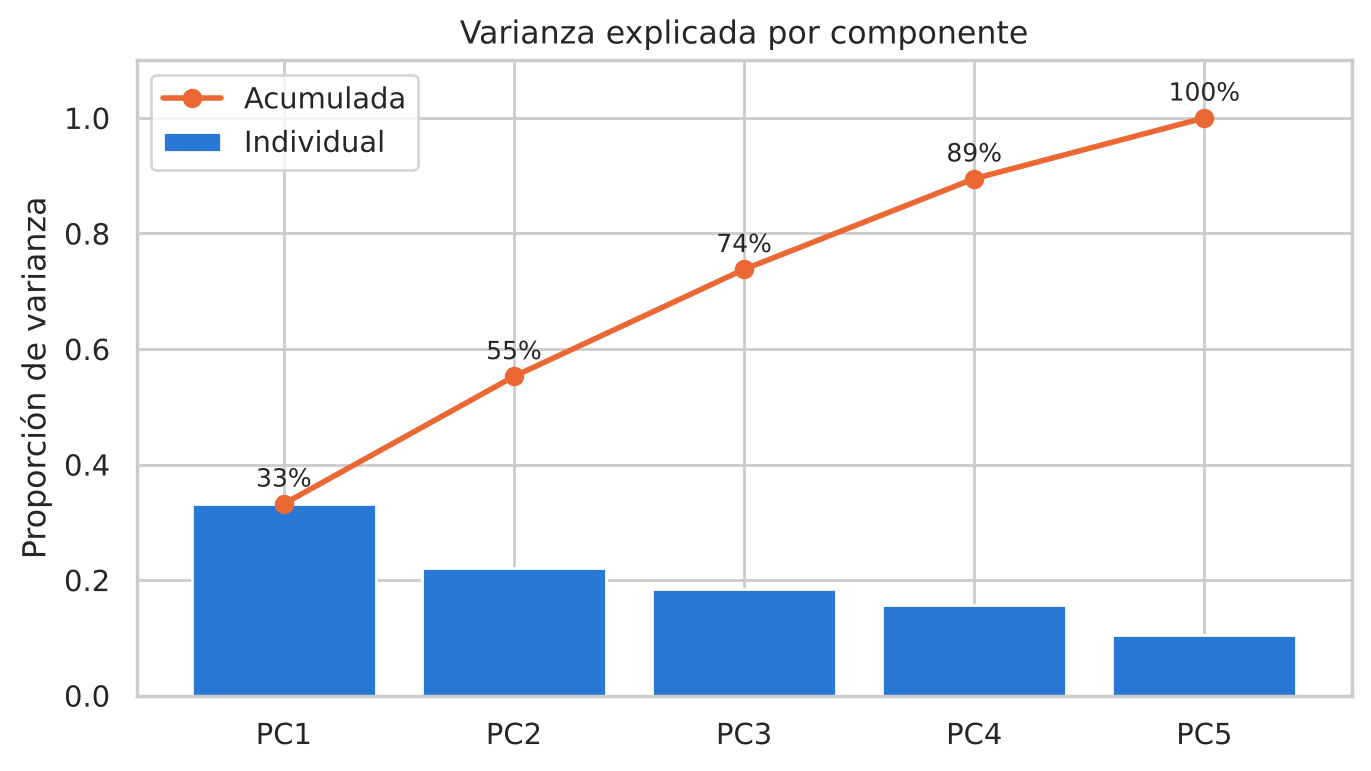

In [28]:
pca = PCA(random_state=SEMILLA).fit(Z)
var = pd.DataFrame({'Varianza explicada': pca.explained_variance_ratio_,
                    'Acumulada': np.cumsum(pca.explained_variance_ratio_)},
                   index=[f'PC{i+1}' for i in range(Z.shape[1])])
display(var)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(var.index, var['Varianza explicada'], color=COLORES[0], label='Individual')
ax.plot(var.index, var['Acumulada'], marker='o', color=COLORES[1], lw=2, label='Acumulada')
for i, v in enumerate(var['Acumulada']):
    ax.text(i, v + 0.03, f'{v:.0%}', ha='center', fontsize=9)
ax.set(ylim=(0, 1.1), ylabel='Proporción de varianza', title='Varianza explicada por componente'); ax.legend()
plt.tight_layout(); plt.show()

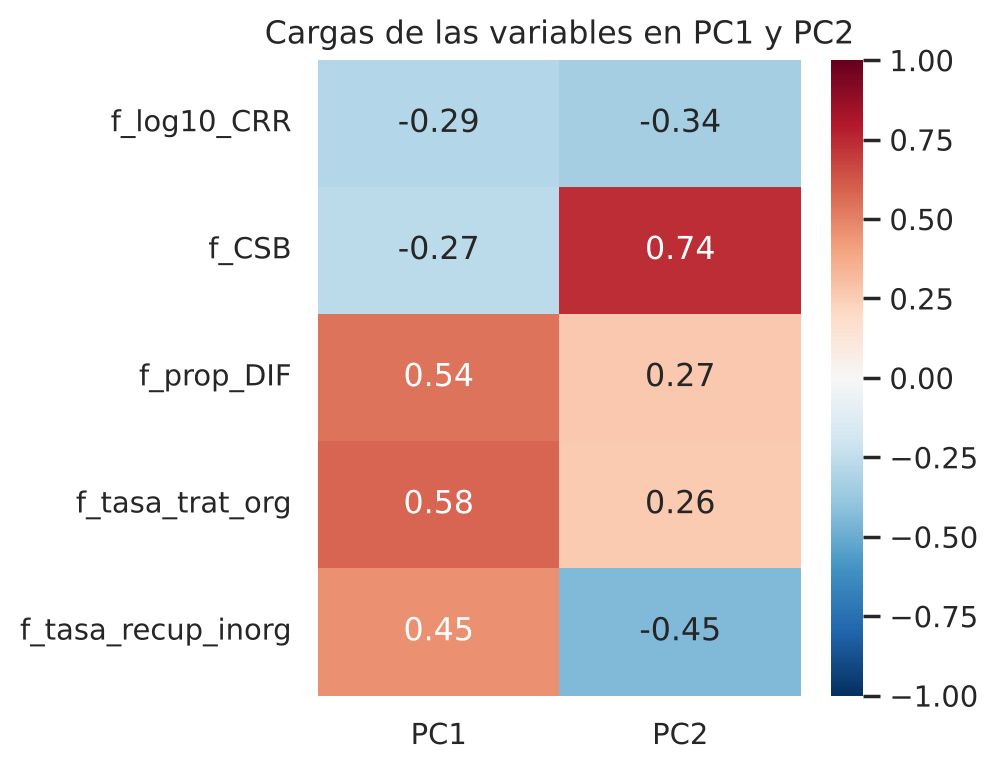

In [29]:
cargas = pd.DataFrame(pca.components_[:2].T, index=FEATURES, columns=['PC1', 'PC2'])
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cargas, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=ax)
ax.set_title('Cargas de las variables en PC1 y PC2')
plt.tight_layout(); plt.show()

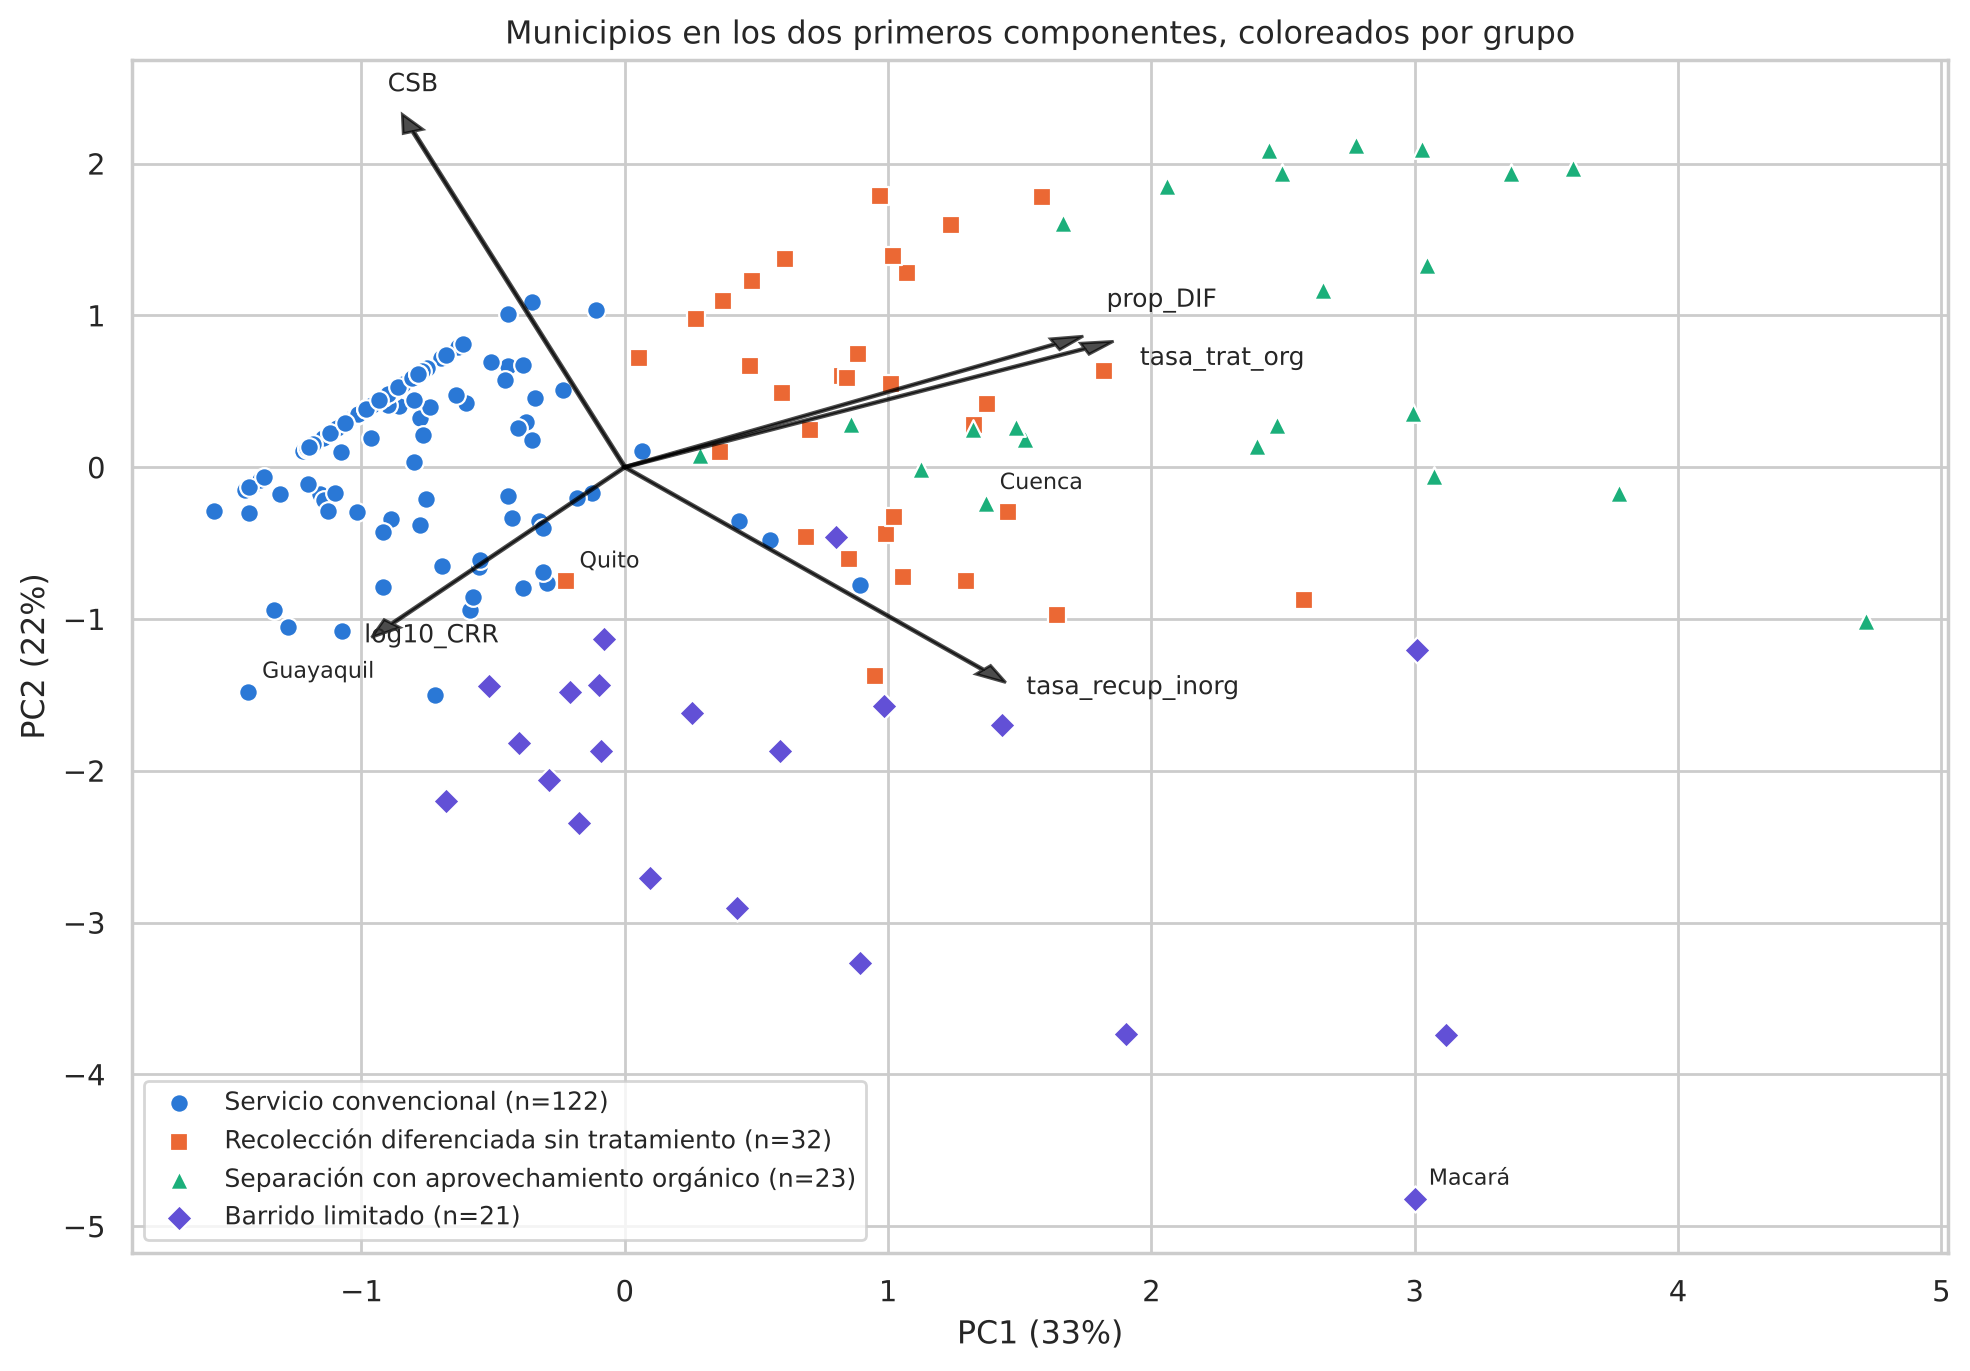

In [30]:
P = pca.transform(Z)[:, :2]
fig, ax = plt.subplots(figsize=(10, 7))
for gname in ORDEN:
    m = (base['grupo'] == gname).values
    ax.scatter(P[m, 0], P[m, 1], s=45, color=COLOR_G[gname], marker=MARCA_G[gname],
               edgecolor='white', linewidth=0.8, label=f'{gname} (n={m.sum()})')
# Flechas de las cargas (escaladas para que se vean)
esc = 3
for f, (a, b_) in cargas.iterrows():
    ax.arrow(0, 0, a * esc, b_ * esc, color='black', width=0.01, head_width=0.08, alpha=0.7)
    dy = {'f_prop_DIF': 0.15, 'f_tasa_trat_org': -0.2}.get(f, 0)    # evitar etiquetas encimadas
    ax.text(a * esc * 1.12, b_ * esc * 1.12 + dy, f.replace('f_', ''), fontsize=9)
# Algunos municipios de referencia
for nom in ['GUAYAQUIL', 'QUITO', 'CUENCA', 'MACARÁ']:
    i = base.index[base['NombreCantón'] == nom]
    if len(i): ax.annotate(nom.title(), P[i[0]], xytext=(5, 5), textcoords='offset points', fontsize=8)
ax.set(xlabel=f'PC1 ({var.iloc[0, 0]:.0%})', ylabel=f'PC2 ({var.iloc[1, 0]:.0%})',
       title='Municipios en los dos primeros componentes, coloreados por grupo')
ax.legend(loc='lower left', fontsize=9, frameon=True)
plt.tight_layout(); plt.show()

**Interpretación.**
- **PC1 (33 %)** tiene cargas positivas altas en tratamiento de orgánicos (0,58), recolección diferenciada (0,54) y recuperación de inorgánicos (0,45). Resume el grado de **separación y aprovechamiento**: a la derecha están los grupos que diferencian y tratan.
- **PC2 (22 %)** está dominado por la **cobertura de barrido** (0,74), en oposición a la recuperación de inorgánicos (−0,45). Abajo se ubica el grupo de barrido limitado.
- La escala (`log10_CRR`) tiene cargas moderadas (≈ −0,3) y no domina ninguno de los dos componentes. Es otra señal de que los grupos no se forman por el tamaño.
- Los dos componentes explican el 55 % de la varianza, así que el gráfico es una aproximación: los grupos que parecen solaparse en 2D se separan mejor en las 5 dimensiones donde se calcularon las métricas.

---
## <font color='264CC7'> 6. Interpretación de los perfiles </font>

### 6.1 Tabla de perfiles en unidades originales

In [31]:
perfil = base.groupby('grupo', observed=True).agg(
    Municipios=('CantonId', 'size'),
    **{'Recolectado, mediana (t/mes)': ('CRR', 'median'),
       'Cobertura de barrido, mediana': ('f_CSB', 'median'),
       '% con recolección diferenciada': ('f_prop_DIF', lambda s: 100 * (s > 0).mean()),
       'Parte diferenciada, media': ('f_prop_DIF', 'mean'),
       '% que trata orgánicos': ('f_tasa_trat_org', lambda s: 100 * (s > 0).mean()),
       'Orgánicos tratados / recolectado, media': ('f_tasa_trat_org', 'mean'),
       '% que recupera inorgánicos': ('f_tasa_recup_inorg', lambda s: 100 * (s > 0).mean()),
       'Inorgánicos recuperados / recolectado, media': ('f_tasa_recup_inorg', 'mean')})
display(perfil.T.style.format('{:,.2f}'))

grupo,Servicio convencional,Recolección diferenciada sin tratamiento,Separación con aprovechamiento orgánico,Barrido limitado
Municipios,122.00,32.00,23.00,21.00
"Recolectado, mediana (t/mes)",435.60,370.50,135.00,423.60
"Cobertura de barrido, mediana",1.00,0.93,0.98,0.32
% con recolección diferenciada,0.82,100.00,82.61,9.52
"Parte diferenciada, media",0.00,0.98,0.63,0.10
% que trata orgánicos,7.38,40.62,100.00,14.29
"Orgánicos tratados / recolectado, media",0.00,0.02,0.41,0.01
% que recupera inorgánicos,21.31,56.25,69.57,61.90
"Inorgánicos recuperados / recolectado, media",0.00,0.01,0.02,0.04


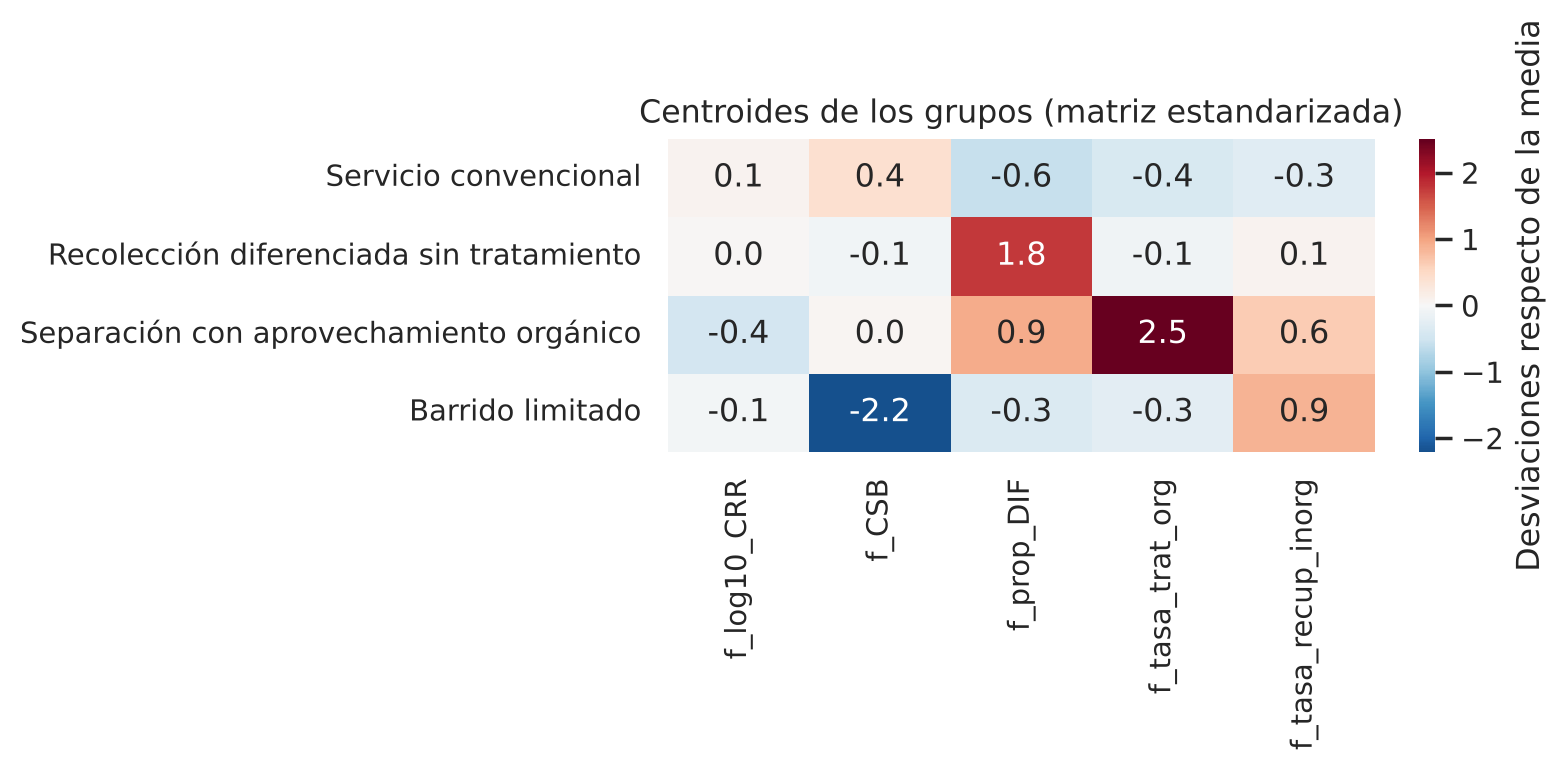

In [32]:
# Perfiles estandarizados: distancia de cada grupo a la media general (en desviaciones estándar)
z_perfil = pd.DataFrame(Z, columns=FEATURES).assign(grupo=base['grupo']).groupby('grupo', observed=True).mean()
fig, ax = plt.subplots(figsize=(8, 3.6))
sns.heatmap(z_perfil, annot=True, fmt='.1f', cmap='RdBu_r', center=0, ax=ax,
            cbar_kws={'label': 'Desviaciones respecto de la media'})
ax.set(title='Centroides de los grupos (matriz estandarizada)', xlabel='', ylabel='')
plt.tight_layout(); plt.show()

In [33]:
# Características descriptivas (no usadas para agrupar)
for var_desc in ['Region', 'Modelo_gestion', 'Disposicion_final', 'Separacion_fuente', 'Balanza']:
    t = pd.crosstab(base['grupo'], base[var_desc], normalize='index').mul(100).round(0)
    print(f'\n% de municipios por {var_desc}')
    display(t)


% de municipios por Region


Region,Amazonía,Costa,Insular,Sierra
grupo,,,,
Servicio convencional,10.000,53.000,0.000,37.000
Recolección diferenciada sin tratamiento,19.000,19.000,6.000,56.000
Separación con aprovechamiento orgánico,48.000,4.000,0.000,48.000
Barrido limitado,33.000,38.000,0.000,29.000



% de municipios por Modelo_gestion


Modelo_gestion,Empresa pública mancomunada,Empresa pública municipal,Gestión combinada,Gestión directa,Mancomunidad
grupo,,,,,
Servicio convencional,5.000,7.000,16.000,70.000,1.000
Recolección diferenciada sin tratamiento,6.000,9.000,6.000,78.000,0.000
Separación con aprovechamiento orgánico,4.000,4.000,4.000,87.000,0.000
Barrido limitado,10.000,5.000,5.000,76.000,5.000



% de municipios por Disposicion_final


Disposicion_final,Botadero,Celda emergente,Relleno sanitario
grupo,,,
Servicio convencional,20.000,29.000,52.000
Recolección diferenciada sin tratamiento,9.000,16.000,75.000
Separación con aprovechamiento orgánico,9.000,9.000,83.000
Barrido limitado,19.000,29.000,52.000



% de municipios por Separacion_fuente


Separacion_fuente,No,Sí
grupo,,
Servicio convencional,94.000,6.000
Recolección diferenciada sin tratamiento,47.000,53.000
Separación con aprovechamiento orgánico,26.000,74.000
Barrido limitado,86.000,14.000



% de municipios por Balanza


Balanza,No,Sí
grupo,,
Servicio convencional,61.000,39.000
Recolección diferenciada sin tratamiento,44.000,56.000
Separación con aprovechamiento orgánico,52.000,48.000
Barrido limitado,71.000,29.000


### 6.2 Descripción de cada perfil

*El orden y los nombres no indican calidad.*

In [34]:
# Ejemplos: los 3 municipios más cercanos al centroide de cada grupo
dist = np.linalg.norm(Z - km_final.cluster_centers_[km_final.labels_], axis=1)
base['dist_centroide'] = dist
ejemplos = (base.sort_values('dist_centroide').groupby('grupo', observed=True).head(3)
            .sort_values(['grupo', 'dist_centroide'])
            [['grupo', 'NombreCantón', 'Provincia', 'CRR', 'f_CSB', 'f_prop_DIF', 'f_tasa_trat_org', 'f_tasa_recup_inorg']])
display(ejemplos)

,grupo,NombreCantón,Provincia,CRR,f_CSB,f_prop_DIF,f_tasa_trat_org,f_tasa_recup_inorg
86,Servicio convencional,NOBOL,Guayas,616.200,0.952,0.000,0.000,0.000
131,Servicio convencional,PAJÁN,Manabí,510.000,1.000,0.000,0.000,0.000
173,Servicio convencional,SANTIAGO DE PÍLLARO,Tungurahua,510.000,1.000,0.000,0.000,0.000
103,Recolección diferenciada sin tratamiento,PUYANGO,Loja,243.900,0.800,1.000,0.018,0.004
25,Recolección diferenciada sin tratamiento,MONTÚFAR,Carchi,720.000,1.000,1.000,0.011,0.004
83,Recolección diferenciada sin tratamiento,SIMÓN BOLÍVAR,Guayas,348.000,0.726,1.000,0.000,0.000
47,Separación con aprovechamiento orgánico,BALSAS,El Oro,100.500,1.000,1.000,0.669,0.008
93,Separación con aprovechamiento orgánico,SAN MIGUEL DE URCUQUÍ,Imbabura,360.000,1.000,1.000,0.364,0.000
176,Separación con aprovechamiento orgánico,NANGARITZA,Zamora Chinchipe,97.500,1.000,1.000,0.197,0.024
54,Barrido limitado,SANTA ROSA,El Oro,"1,598.700",0.231,0.000,0.000,0.006


| Perfil | Lo que lo distingue | Oportunidades de mejora | Información adicional necesaria |
|---|---|---|---|
| **Servicio convencional** (122) | Barrido completo (mediana 1,0) y recolección **sin diferenciar**. Solo el 7 % trata orgánicos y el 21 % recupera inorgánicos. Solo el 6 % declara separación en la fuente. Es el perfil más común, en municipios de todos los tamaños. | Pilotos de separación en la fuente y recolección diferenciada en barrios; acuerdos con recicladores de base. | Composición de sus residuos (pocos tienen caracterización), costos del servicio y capacidad de los sitios de disposición. |
| **Recolección diferenciada sin tratamiento** (32) | Todos diferencian, y en promedio el 97 % de lo que recolectan llega diferenciado. Sin embargo, los orgánicos tratados equivalen a menos del 2 % de lo recolectado. Tres de cada cuatro usan relleno sanitario. | Revisar el destino de los orgánicos separados; si van al mismo sitio de disposición, se pierde el esfuerzo de separar. Evaluar compostaje o convenios. | Destino final de cada fracción y capacidad de tratamiento disponible. |
| **Separación con aprovechamiento orgánico** (23) | Todos tratan orgánicos (en promedio, el equivalente al 41 % de lo recolectado) y el 83 % diferencia la recolección. Son municipios más pequeños (mediana 135 t/mes) de la Sierra y la Amazonía. | Documentar y compartir su experiencia con municipios similares; buscar mercado para el compost. | Confirmar las unidades reportadas de orgánicos tratados (kg/mes) y la calidad del producto final. |
| **Barrido limitado** (21) | La cobertura de barrido es mucho más baja (mediana ≈ 0,3). Casi no diferencia ni trata orgánicos, pero el 62 % recupera inorgánicos y su tasa media es la más alta (4 %). Hay más municipios de la Costa y la Amazonía. | Revisar la planificación de rutas de barrido y si la longitud barrible está bien medida. | Longitud real de calles pavimentadas, frecuencia de barrido y personal disponible. |

### 6.3 Municipios poco representados

In [35]:
print('Municipios con silueta negativa (más cerca de otro grupo que del propio):')
display(base.loc[base['silueta'] < 0, ['NombreCantón', 'grupo', 'silueta', 'CRR', 'f_CSB',
                                       'f_prop_DIF', 'f_tasa_trat_org', 'f_tasa_recup_inorg']]
            .sort_values('silueta'))

Municipios con silueta negativa (más cerca de otro grupo que del propio):


,NombreCantón,grupo,silueta,CRR,f_CSB,f_prop_DIF,f_tasa_trat_org,f_tasa_recup_inorg
187,SUCUMBÍOS,Barrido limitado,-0.191,45.300,0.679,0.000,0.021,0.011
23,BOLÍVAR,Separación con aprovechamiento orgánico,-0.185,285.000,0.809,0.191,0.143,0.002
148,SAN JUAN BOSCO,Separación con aprovechamiento orgánico,-0.125,36.000,1.000,0.000,0.069,0.043
183,LAGO AGRIO,Barrido limitado,-0.079,"1,907.100",0.589,0.000,0.000,0.017
1,GIRÓN,Barrido limitado,-0.066,129.000,0.284,1.000,0.109,0.018
194,SANTO DOMINGO,Separación con aprovechamiento orgánico,-0.035,"10,659.000",0.877,0.028,0.362,0.000
63,RIOVERDE,Barrido limitado,-0.033,"1,050.000",0.474,0.000,0.000,0.000
184,GONZALO PIZARRO,Barrido limitado,-0.021,122.400,0.700,0.000,0.000,0.069
142,MORONA,Separación con aprovechamiento orgánico,-0.020,606.000,1.000,1.000,0.248,0.000


Estos municipios tienen combinaciones intermedias, por ejemplo cobertura de barrido media con algo de recolección diferenciada, y no encajan bien en ningún perfil. En ellos la asignación es poco segura.

In [36]:
# Asignación tentativa de los 23 municipios excluidos: centroide más cercano usando solo
# las características que sí tienen (no se imputa ningún valor)
excl = df[~df['incluir_matriz']].copy()
Xe = excl[FEATURES].copy()
Xe['f_tasa_trat_org'] = np.sqrt(Xe['f_tasa_trat_org']); Xe['f_tasa_recup_inorg'] = np.sqrt(Xe['f_tasa_recup_inorg'])
Ze = (Xe.values - escalador.mean_) / escalador.scale_
C = km_final.cluster_centers_
asig = []
for fila in Ze:
    ok = ~np.isnan(fila)
    asig.append(nombres[np.argmin(((C[:, ok] - fila[ok]) ** 2).sum(axis=1))])
excl['grupo_tentativo'] = asig
display(excl[['NombreCantón', 'motivo_exclusion', 'grupo_tentativo', 'CRR', 'TROT']].sort_values('grupo_tentativo'))

,NombreCantón,motivo_exclusion,grupo_tentativo,CRR,TROT
217,LA CONCORDIA,TROT no_confiable,Barrido limitado,"1,374.600","2,734.320"
201,PAQUISHA,TROT no_confiable,Barrido limitado,61.200,109.460
16,CHILLANES,TROT faltante; RI faltante,Barrido limitado,270.000,0.000
188,PATATE,CSB faltante,Barrido limitado,234.000,0.000
24,CAÑAR,TROT no_confiable,Barrido limitado,400.800,"1,734.660"
204,SANTA CRUZ,TROT no_confiable,Barrido limitado,437.100,963.190
59,MARCABELÍ,TROT no_confiable,Barrido limitado,133.800,541.770
182,PEDRO VICENTE MALDONADO,TROT no_confiable,Recolección diferenciada sin tratamiento,335.700,"2,489.420"
99,ANTONIO ANTE,TROT no_confiable,Recolección diferenciada sin tratamiento,681.900,"3,721.560"
6,SAN FERNANDO,RI faltante,Recolección diferenciada sin tratamiento,100.800,0.800


Los 16 municipios con `TROT` no confiable sí tratan orgánicos. Aun sin usar esa variable, 8 de ellos se asignan a *Separación con aprovechamiento orgánico* por su recolección diferenciada. Ese perfil está **subrepresentado**: en la matriz tiene 23 municipios, pero podrían ser más de 30 si se confirman las unidades de `MR4441`.

### 6.4 Discusión de estabilidad: ¿qué conclusiones se mantienen?

| Cambio | Qué se observa | Conclusión |
|---|---|---|
| **Semilla de K-Means** | Con 10 inicializaciones, las 30 semillas dan casi la misma partición (ARI medio ≈ 0,98). Con una sola inicialización, no. | Los perfiles no dependen de la semilla si se usan varias inicializaciones. |
| **Método** (K-Means vs Ward) | Para k = 4, la mayoría de los municipios cae en grupos equivalentes (ARI ≈ 0,7). | Los cuatro perfiles aparecen con los dos algoritmos. |
| **Número de grupos** | k = 2 separa a quienes diferencian de quienes no. k = 3 agrega el barrido limitado. k = 5 agrega un grupo pequeño con alta recuperación de inorgánicos. | Hay dos ejes que siempre aparecen: **separación/aprovechamiento** y **cobertura de barrido**. El *Servicio convencional* aparece en todas las soluciones. |
| **Submuestras del 80 %** | ARI medio ≈ 0,86. | Estabilidad aceptable, con límites entre grupos vecinos que son graduales. |
| **Transformación de las tasas** | Sin raíz cuadrada aparecen grupos de 2–4 municipios extremos. | Los perfiles principales dependen de cómo se traten los atípicos; la raíz evita que pocos casos definan un grupo. |

---
## <font color='264CC7'> 7. Conclusiones </font>

### Respuesta a la pregunta de análisis
En los registros 2024 aparecen **cuatro perfiles de gestión**: *servicio convencional* (la mayoría), *recolección diferenciada sin tratamiento*, *separación con aprovechamiento orgánico* y *barrido limitado*. Se distinguen por dos ejes: el grado de **separación y aprovechamiento** de los residuos y la **cobertura del barrido**. Comunicarlos como perfiles de práctica, y no como un ranking, ayuda a plantear preguntas concretas a cada tipo de municipio.

### Respuesta a las preguntas guía
- **¿Prácticas o tamaño?** Con indicadores relativos, los grupos reflejan **prácticas**: la escala casi no se correlaciona con las demás características y no domina el PCA. La mediana de recolección es parecida en tres de los cuatro grupos (370–436 t/mes). Con cantidades absolutas, los grupos se ordenan por tamaño.
- **Cero, faltante y no aplica.** Un cero es una actividad que no se realiza. Un faltante es una actividad sin cantidad reportada. "No aplica" corresponde a un servicio inexistente. Se trataron por separado (sección 3.5); confundirlos habría creado perfiles falsos de "baja cobertura" o "sin tratamiento".
- **Absolutas vs relativas.** Con absolutas, variables como los km barridos repiten el tamaño y los grupos se ordenan de pequeños a grandes. Las relativas permiten comparar municipios de distinto tamaño.
- **Qué distingue a los grupos y quién queda poco representado.** Los distinguen la recolección diferenciada, el tratamiento de orgánicos y la cobertura de barrido. Quedan poco representados los 9 municipios con silueta negativa (perfiles intermedios) y los 16 excluidos por unidades dudosas de `TROT`, que sí tratan orgánicos.
- **Qué permanece al cambiar k o la inicialización.** El servicio convencional y los dos ejes (separación y barrido) aparecen con distintos k, con los dos métodos y con distintas semillas cuando se usan varias inicializaciones.

### Resumen técnico
- Matriz de 198 municipios × 5 características, estandarizada, con raíz cuadrada en las dos tasas.
- K-Means y Ward (euclidiana) para k = 2…6. Silueta entre 0,39 y 0,41 para k = 2…5. Se eligió **K-Means, k = 4** (silueta ≈ 0,41; tamaños 122/32/23/21).
- Estable frente a semillas con `n_init` = 10 (ARI ≈ 0,98) y razonablemente estable frente a submuestras (ARI ≈ 0,86).
- PCA: dos componentes explican el 55 % de la varianza. Se usaron solo para visualizar.

### Limitaciones
- La silueta es moderada (≈ 0,4): los perfiles tienen bordes graduales, no son categorías nítidas.
- Las características con exceso de ceros pesan mucho en la distancia.
- 23 municipios quedaron fuera por datos faltantes o no confiables. Entre ellos están casos relevantes de aprovechamiento orgánico.
- Es una sola edición y son datos autorreportados. No se mide calidad del servicio, costos ni impacto ambiental.
- La corrección de la longitud barrible usa los componentes y no el total. En dos municipios (Chunchi y Guano) esta decisión cambia mucho la cobertura.

### Posibles mejoras
- Confirmar con los GAD la unidad de `MR4441` y reincorporar los 16 municipios.
- Contar con la población total cantonal de 2024 para construir indicadores por habitante.
- Probar métodos más adecuados para datos con muchos ceros, por ejemplo distancias para datos mixtos o modelos de mezcla.
- Repetir el análisis con otras ediciones para ver si los municipios cambian de perfil.